Table 1 figure

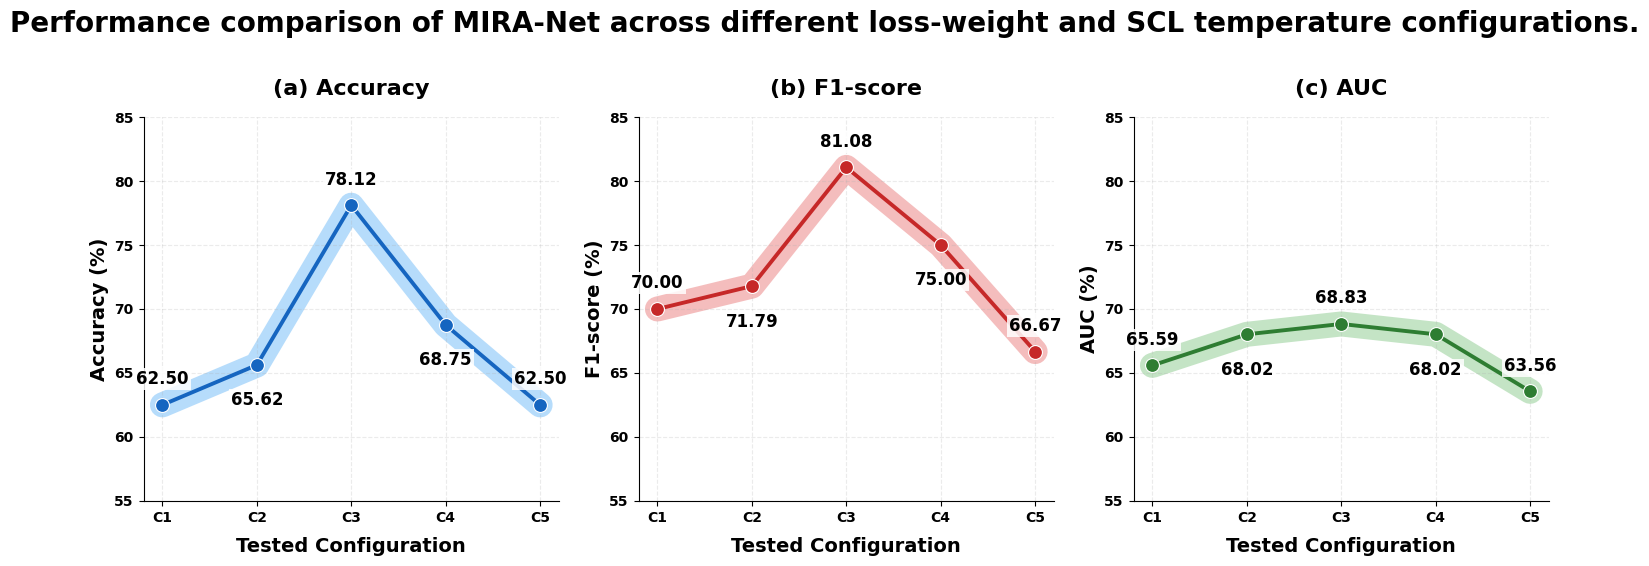

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Figure 3: MIRA-Net configuration comparison
# Bold labels, common y-axis range, and highlighted lines
# ============================================================

configurations = ["C1", "C2", "C3", "C4", "C5"]
x = np.arange(len(configurations))

# Table 16 results
accuracy = [62.50, 65.62, 78.12, 68.75, 62.50]
f1_score = [0.7000, 0.7179, 0.8108, 0.7500, 0.6667]
auc = [0.6559, 0.6802, 0.6883, 0.6802, 0.6356]

# Convert all metrics to percentage scale for a common 55–85 y-axis.
f1_percent = np.array(f1_score) * 100
auc_percent = np.array(auc) * 100

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))

plots = [
    (axes[0], accuracy, "Accuracy (%)", "%.2f",
     "#1565C0", "#90CAF9"),
    (axes[1], f1_percent, "F1-score (%)", "%.2f",
     "#C62828", "#EF9A9A"),
    (axes[2], auc_percent, "AUC (%)", "%.2f",
     "#2E7D32", "#A5D6A7")
]

for ax, values, ylabel, fmt, line_color, highlight_color in plots:

    # Light, wide highlight following the entire line
    ax.plot(
        x, values,
        color=highlight_color,
        linewidth=18,
        alpha=0.65,
        solid_capstyle="round",
        zorder=1
    )

    # Dark main line
    ax.plot(
        x, values,
        color=line_color,
        linewidth=2.8,
        marker="o",
        markersize=10,
        markerfacecolor=line_color,
        markeredgecolor="white",
        markeredgewidth=0.8,
        solid_capstyle="round",
        zorder=2
    )

    # Bold black values, offset above or below the line to prevent overlap
    for i, (xi, yi) in enumerate(zip(x, values)):
        offset = 12 if i in [0, 2, 4] else -19

        ax.annotate(
            fmt % yi,
            (xi, yi),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va="bottom" if offset > 0 else "top",
            fontsize=12,
            fontweight="bold",
            color="black",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=1.5
            ),
            zorder=4
        )

    # Axis labels and ticks in bold
    ax.set_xticks(x)
    ax.set_xticklabels(
        configurations,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Tested Configuration",
        fontsize=14,
        fontweight="bold",
        labelpad=9
    )

    ax.set_ylabel(
        ylabel,
        fontsize=14,
        fontweight="bold"
    )

    # Common y-axis range across all three panels
    ax.set_ylim(55, 85)
    ax.set_yticks(np.arange(55, 86, 5))
    ax.tick_params(axis="both", labelsize=10)

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(True, linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_title("(a) Accuracy", fontsize=16, fontweight="bold", pad=16)
axes[1].set_title("(b) F1-score", fontsize=16, fontweight="bold", pad=16)
axes[2].set_title("(c) AUC", fontsize=16, fontweight="bold", pad=16)

fig.suptitle(
    "Performance comparison of MIRA-Net across different loss-weight and SCL temperature configurations.",
    fontsize=20,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "Figure_3_MIRA_Net_Line_Highlight.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_MIRA_Net_Line_Highlight.pdf",
    bbox_inches="tight"
)

plt.show()

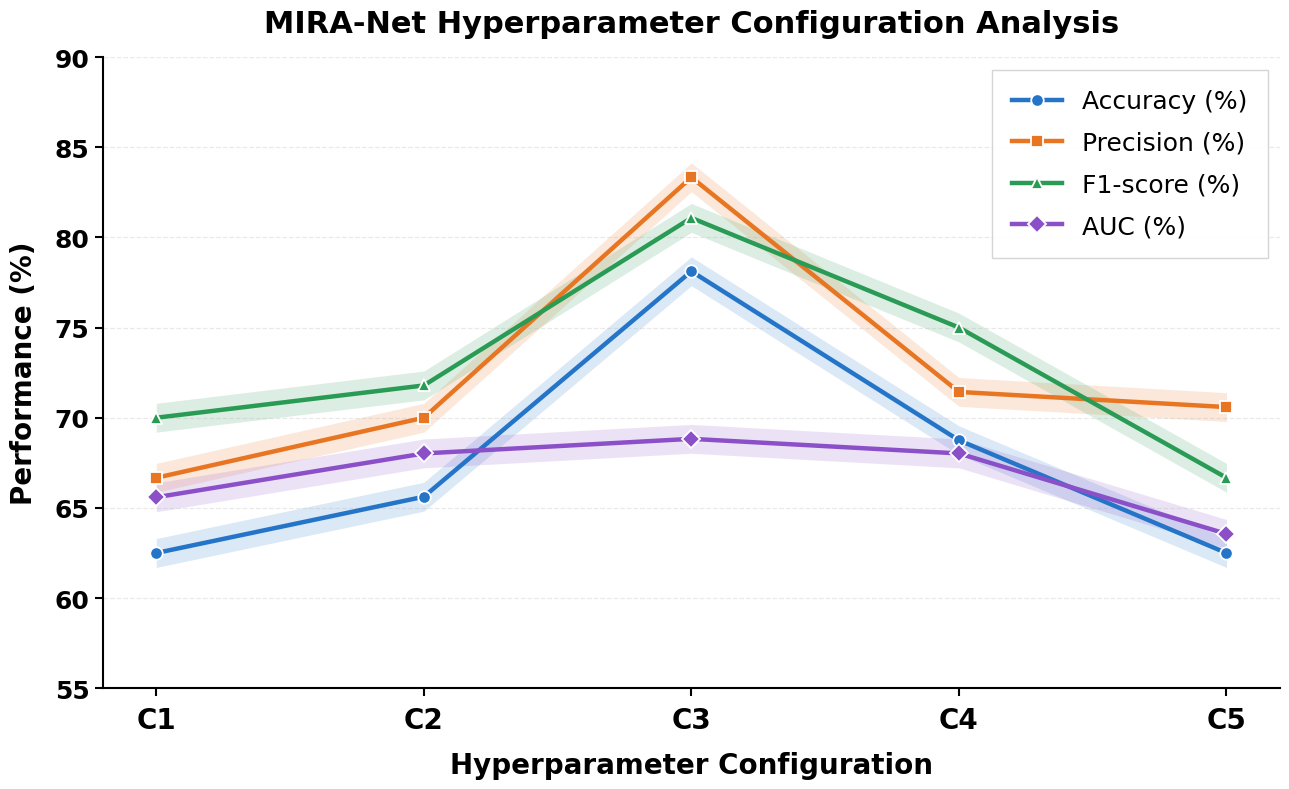

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Figure 5: MIRA-Net Hyperparameter Configuration Analysis
# Publication-quality multi-line graph with shaded bands
# ============================================================

configs = ["C1", "C2", "C3", "C4", "C5"]
x = np.arange(len(configs))

# Table 16 results (all expressed as percentages)
accuracy  = np.array([62.50, 65.62, 78.12, 68.75, 62.50])
precision = np.array([66.67, 70.00, 83.33, 71.43, 70.59])
f1_score  = np.array([70.00, 71.79, 81.08, 75.00, 66.67])
auc       = np.array([65.59, 68.02, 68.83, 68.02, 63.56])

# High-resolution figure
fig, ax = plt.subplots(figsize=(13, 8))

# Light-coloured shading around each line
band_width = 0.8

series = [
    (accuracy, "Accuracy (%)", "#2474C8", "o"),
    (precision, "Precision (%)", "#E87522", "s"),
    (f1_score, "F1-score (%)", "#299B55", "^"),
    (auc, "AUC (%)", "#8B50C7", "D")
]

for values, label, color, marker in series:

    # Soft, light-coloured band around the line
    ax.fill_between(
        x,
        values - band_width,
        values + band_width,
        color=color,
        alpha=0.16,
        linewidth=0,
        zorder=1
    )

    # Main line and markers
    ax.plot(
        x,
        values,
        color=color,
        linewidth=3.2,
        marker=marker,
        markersize=9,
        markerfacecolor=color,
        markeredgecolor="white",
        markeredgewidth=1.3,
        label=label,
        zorder=3
    )

# X-axis formatting
ax.set_xticks(x)
ax.set_xticklabels(
    configs,
    fontsize=20,
    fontweight="bold"
)

ax.set_xlabel(
    "Hyperparameter Configuration",
    fontsize=20,
    fontweight="bold",
    labelpad=12
)

# Y-axis formatting
ax.set_ylabel(
    "Performance (%)",
    fontsize=20,
    fontweight="bold",
    labelpad=12
)

ax.set_ylim(55, 90)
ax.set_yticks(np.arange(55, 91, 5))

ax.tick_params(
    axis="y",
    labelsize=18,
    width=1.5,
    length=6
)

ax.tick_params(
    axis="x",
    width=1.5,
    length=6,
    pad=7
)

# Bold Y-axis tick labels
for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

# Figure title
ax.set_title(
    "MIRA-Net Hyperparameter Configuration Analysis",
    fontsize=22,
    fontweight="bold",
    pad=18
)

# Grid and borders
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.9,
    alpha=0.28,
    zorder=0
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

# Legend
ax.legend(
    loc="best",
    fontsize=18,
    frameon=True,
    fancybox=False,
    edgecolor="lightgray",
    framealpha=0.95,
    borderpad=0.8,
    labelspacing=0.7
)

plt.tight_layout()

# Save publication-quality PNG at 600 DPI
fig.savefig(
    "Figure_5_MIRA_Net_Hyperparameter_Analysis.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

# Save vector-based PDF
fig.savefig(
    "Figure_5_MIRA_Net_Hyperparameter_Analysis.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()





In [ ]:
# Download both files in Google Colab
from google.colab import files

files.download(
    "Figure_5_MIRA_Net_Hyperparameter_Analysis.png"
)

files.download(
    "Figure_5_MIRA_Net_Hyperparameter_Analysis.pdf"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Table 2 figure

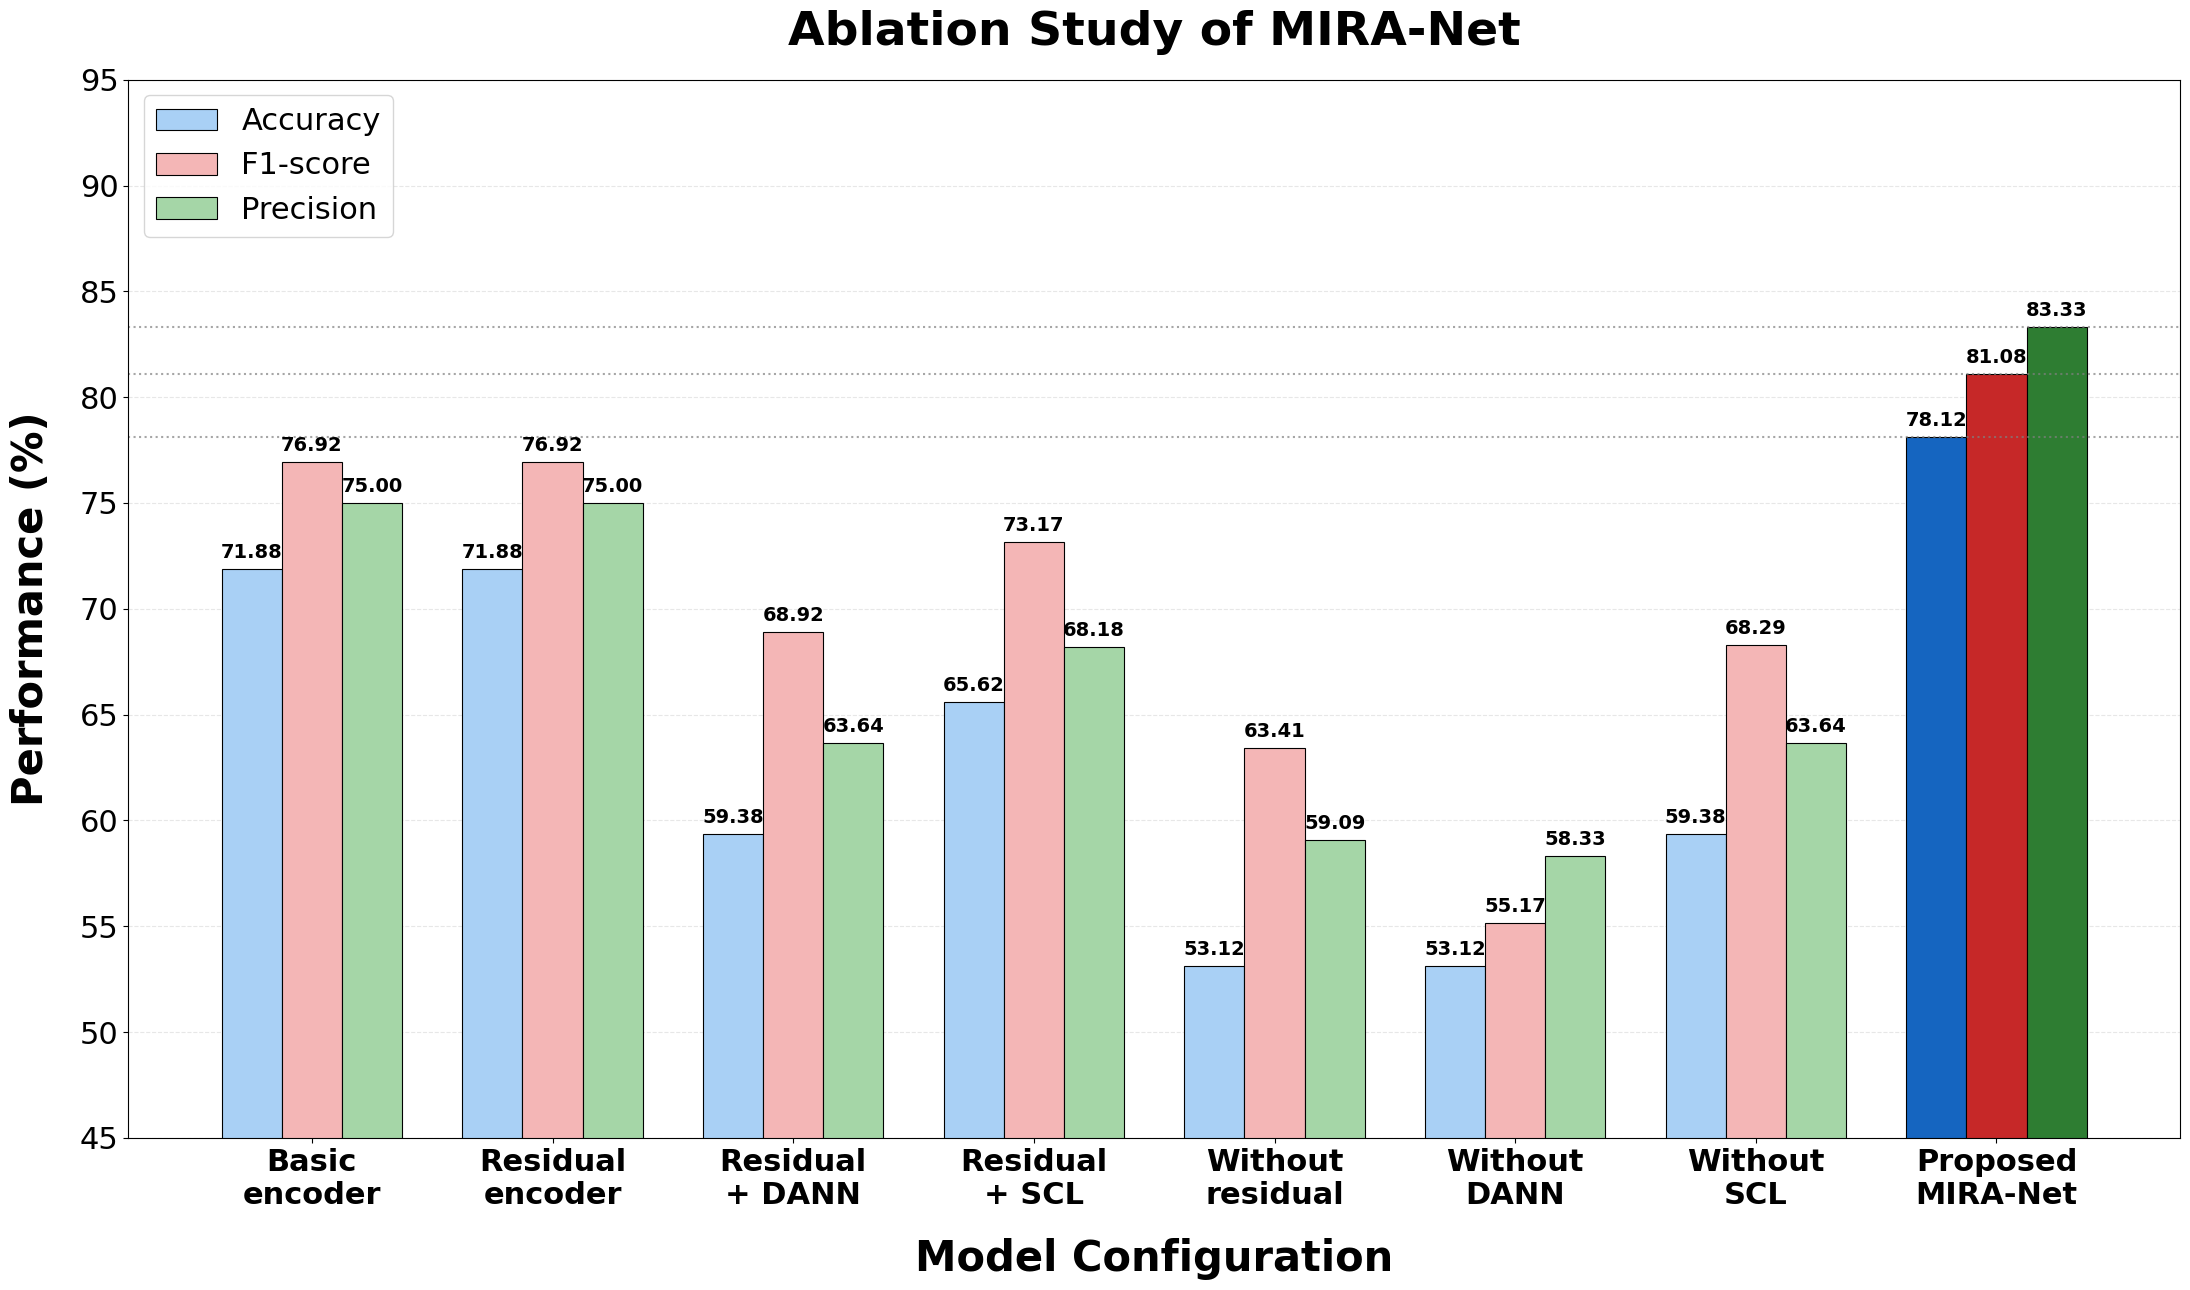

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# MIRA-Net Ablation Study
# Accuracy, Precision, and F1-score on the Same Graph
# ============================================================

models = [
    "Basic\nencoder",
    "Residual\nencoder",
    "Residual\n+ DANN",
    "Residual\n+ SCL",
    "Without\nresidual",
    "Without\nDANN",
    "Without\nSCL",
    "Proposed\nMIRA-Net"
]

# Performance values (%)
accuracy = [
    71.88, 71.88, 59.38, 65.62,
    53.12, 53.12, 59.38, 78.12
]

# Precision values from Table 17
precision = [
    75.00, 75.00, 63.64, 68.18,
    59.09, 58.33, 63.64, 83.33
]

# F1-score values (%)
f1_score = [
    76.92, 76.92, 68.92, 73.17,
    63.41, 55.17, 68.29, 81.08
]

# ============================================================
# COLOURS: ORIGINAL COLOURS RETAINED
# ============================================================

acc_colors = ["#A9D0F5"] * 7 + ["#1565C0"]
f1_colors = ["#F4B6B6"] * 7 + ["#C62828"]

# Precision in green
precision_colors = ["#A5D6A7"] * 7 + ["#2E7D32"]

# ============================================================
# PLOT
# ============================================================

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(22, 13))

# Accuracy bars
bars1 = ax.bar(
    x - width,
    accuracy,
    width,
    label="Accuracy",
    color=acc_colors,
    edgecolor="black",
    linewidth=0.8
)

# F1-score bars
bars2 = ax.bar(
    x,
    f1_score,
    width,
    label="F1-score",
    color=f1_colors,
    edgecolor="black",
    linewidth=0.8
)

# Precision bars in green
bars3 = ax.bar(
    x + width,
    precision,
    width,
    label="Precision",
    color=precision_colors,
    edgecolor="black",
    linewidth=0.8
)

# ============================================================
# VALUE LABELS: INCREASED FONT SIZE
# ============================================================

ax.bar_label(
    bars1,
    fmt="%.2f",
    padding=5,
    fontsize=14,
    fontweight="bold"
)

ax.bar_label(
    bars2,
    fmt="%.2f",
    padding=5,
    fontsize=14,
    fontweight="bold"
)

ax.bar_label(
    bars3,
    fmt="%.2f",
    padding=5,
    fontsize=14,
    fontweight="bold"
)

# ============================================================
# REFERENCE LINES FOR PROPOSED MIRA-NET
# ============================================================

ax.axhline(
    y=accuracy[-1],
    color="grey",
    linestyle=":",
    linewidth=1.5,
    alpha=0.7
)

ax.axhline(
    y=f1_score[-1],
    color="grey",
    linestyle=":",
    linewidth=1.5,
    alpha=0.7
)

ax.axhline(
    y=precision[-1],
    color="grey",
    linestyle=":",
    linewidth=1.5,
    alpha=0.7
)

# ============================================================
# AXIS LABELS AND TITLE: INCREASED FONT SIZE
# ============================================================

ax.set_xlabel(
    "Model Configuration",
    fontsize=30,
    fontweight="bold",
    labelpad=20
)

ax.set_ylabel(
    "Performance (%)",
    fontsize=30,
    fontweight="bold",
    labelpad=20
)

ax.set_title(
    "Ablation Study of MIRA-Net",
    fontsize=34,
    fontweight="bold",
    pad=25
)

ax.set_xticks(x)

ax.set_xticklabels(
    models,
    fontsize=22,
    fontweight="bold"
)

ax.set_ylim(45, 95)
ax.set_yticks(np.arange(45, 96, 5))

# Increase Y-axis tick-label size
ax.tick_params(axis="y", labelsize=22)

# Legend
ax.legend(
    fontsize=22,
    loc="upper left",
    frameon=True
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()

# ============================================================
# SAVE HIGH-RESOLUTION FIGURES FOR THE MANUSCRIPT
# ============================================================

plt.savefig(
    "Figure_4_MIRA_Net_Ablation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_4_MIRA_Net_Ablation.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Download files in Google Colab
from google.colab import files

files.download("Figure_4_MIRA_Net_Ablation.png")
files.download("Figure_4_MIRA_Net_Ablation.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Table 3 figure

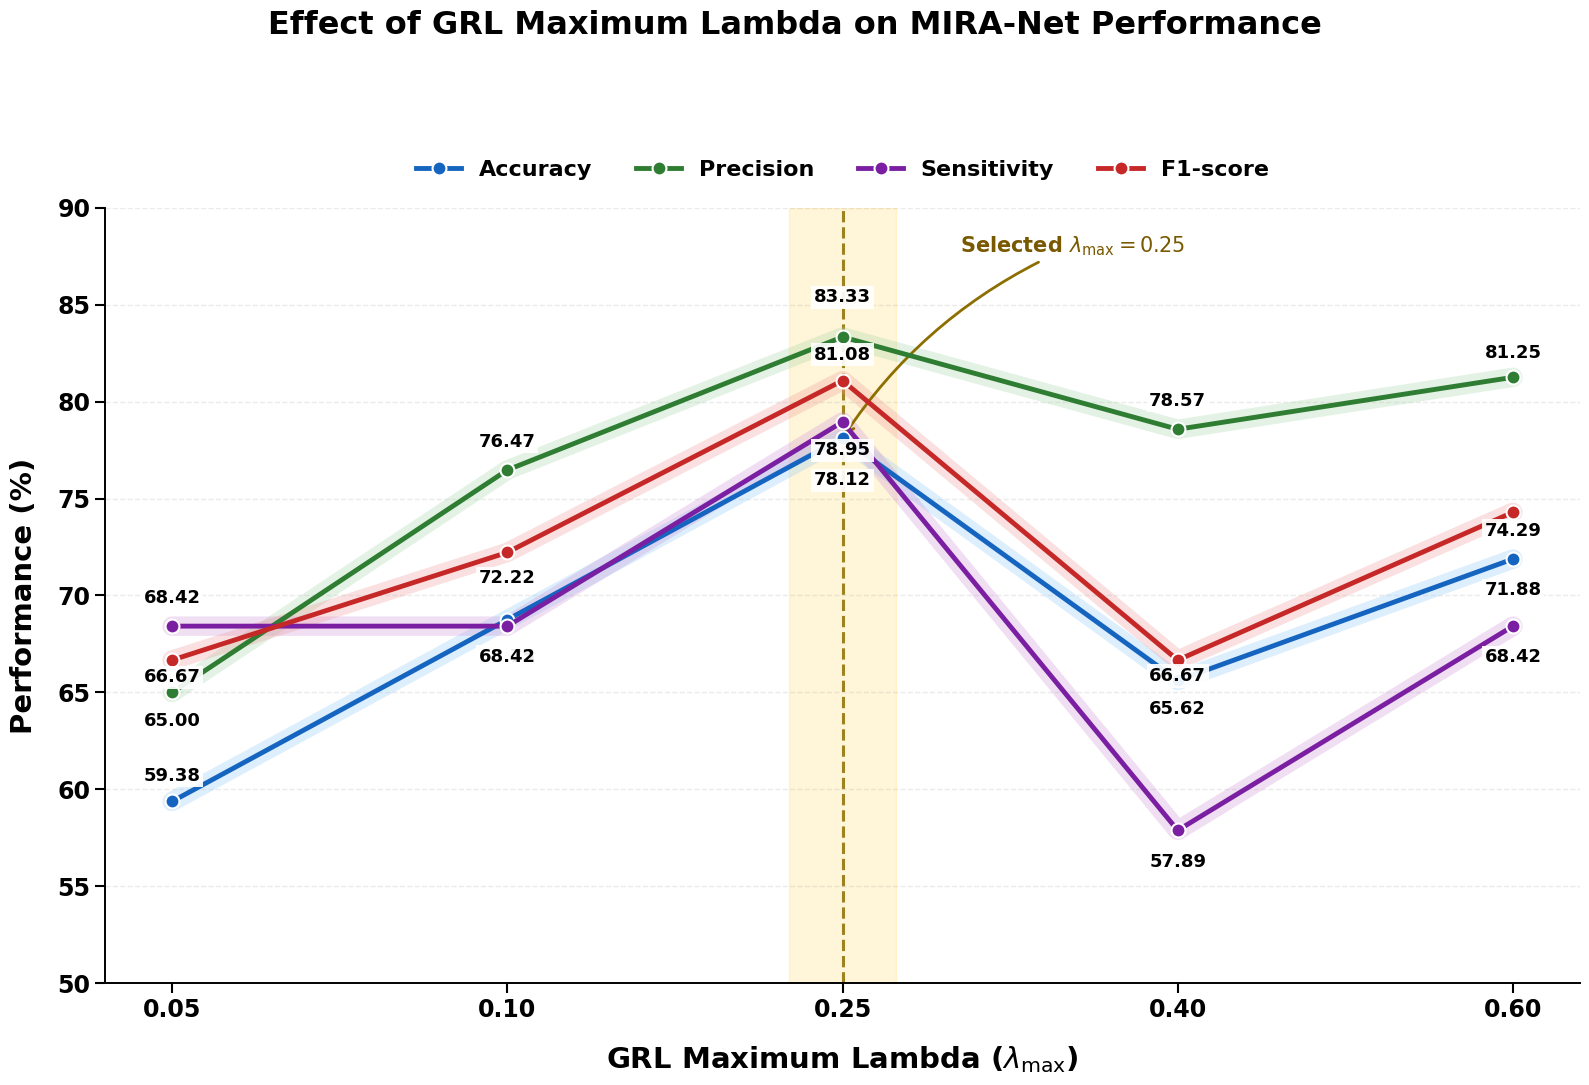

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Figure 5: Effect of GRL Maximum Lambda on MIRA-Net
# Four-metric sensitivity plot with highlighted lambda = 0.25
# Enhanced font sizes for manuscript readability
# ============================================================

grl_lambda = [0.05, 0.10, 0.25, 0.40, 0.60]
x = np.arange(len(grl_lambda))

# Table 18 results
accuracy = [59.38, 68.75, 78.12, 65.62, 71.88]
precision = [0.6500, 0.7647, 0.8333, 0.7857, 0.8125]
sensitivity = [0.6842, 0.6842, 0.7895, 0.5789, 0.6842]
f1_score = [0.6667, 0.7222, 0.8108, 0.6667, 0.7429]

# Convert all metrics to percentages
precision_percent = np.array(precision) * 100
sensitivity_percent = np.array(sensitivity) * 100
f1_percent = np.array(f1_score) * 100

# ============================================================
# FIGURE SETUP
# ============================================================

fig, ax = plt.subplots(figsize=(16, 10))

series = [
    (accuracy, "Accuracy", "#1565C0", "#90CAF9"),
    (precision_percent, "Precision", "#2E7D32", "#A5D6A7"),
    (sensitivity_percent, "Sensitivity", "#7B1FA2", "#CE93D8"),
    (f1_percent, "F1-score", "#C62828", "#EF9A9A")
]

# Highlight the selected GRL maximum lambda
selected_index = grl_lambda.index(0.25)

ax.axvspan(
    selected_index - 0.16,
    selected_index + 0.16,
    color="#FFD54F",
    alpha=0.22,
    zorder=0
)

ax.axvline(
    selected_index,
    color="#8D6E00",
    linestyle="--",
    linewidth=2.2,
    alpha=0.85,
    zorder=1
)

# Individual label offsets to reduce overlapping
label_offsets = {
    "Accuracy":    [12, -20, -24, -14, -16],
    "Precision":   [-14, 14, 22, 14, 11],
    "Sensitivity": [14, -16, -14, -16, -16],
    "F1-score":    [-6, -12, 12, -5, -7]
}

# ============================================================
# PLOT LINES AND VALUE LABELS
# ============================================================

for values, label, line_color, highlight_color in series:

    # Soft, wide highlight following each line
    ax.plot(
        x, values,
        color=highlight_color,
        linewidth=14,
        alpha=0.30,
        solid_capstyle="round",
        zorder=2
    )

    # Main line and circular markers
    ax.plot(
        x, values,
        color=line_color,
        linewidth=3.5,
        marker="o",
        markersize=10,
        markerfacecolor=line_color,
        markeredgecolor="white",
        markeredgewidth=1.5,
        label=label,
        zorder=4
    )

    # Numerical labels with larger font
    for i, (xi, yi) in enumerate(zip(x, values)):
        offset = label_offsets[label][i]

        ax.annotate(
            f"{yi:.2f}",
            (xi, yi),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va="bottom" if offset > 0 else "top",
            fontsize=13,
            fontweight="bold",
            color="black",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.92,
                pad=1.8
            ),
            zorder=5
        )

# ============================================================
# X-AXIS FORMATTING
# ============================================================

ax.set_xticks(x)

ax.set_xticklabels(
    [f"{value:.2f}" for value in grl_lambda],
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel(
    r"GRL Maximum Lambda ($\lambda_{\max}$)",
    fontsize=21,
    fontweight="bold",
    labelpad=16
)

# ============================================================
# Y-AXIS FORMATTING
# ============================================================

ax.set_ylabel(
    "Performance (%)",
    fontsize=21,
    fontweight="bold",
    labelpad=14
)

ax.set_ylim(50, 90)
ax.set_yticks(np.arange(50, 91, 5))

ax.tick_params(
    axis="both",
    labelsize=17,
    width=1.5,
    length=7
)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

# ============================================================
# SELECTED CONFIGURATION ANNOTATION
# ============================================================

ax.annotate(
    r"Selected $\lambda_{\max}=0.25$",
    xy=(selected_index, 78.12),
    xytext=(selected_index + 0.35, 88.0),
    fontsize=15,
    fontweight="bold",
    color="#795900",
    arrowprops=dict(
        arrowstyle="->",
        color="#8D6E00",
        linewidth=2.0,
        connectionstyle="arc3,rad=0.15"
    ),
    ha="left",
    va="center",
    annotation_clip=False
)

# ============================================================
# GRID AND SPINES
# ============================================================

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
    linewidth=1.0,
    zorder=0
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.4)
ax.spines["bottom"].set_linewidth(1.4)

# ============================================================
# LEGEND
# ============================================================

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=4,
    frameon=False,
    fontsize=16,
    prop={"weight": "bold", "size": 16}
)

# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(
    "Effect of GRL Maximum Lambda on MIRA-Net Performance",
    fontsize=23,
    fontweight="bold",
    y=1.08
)

plt.tight_layout()

# ============================================================
# SAVE HIGH-RESOLUTION FIGURES
# ============================================================

plt.savefig(
    "Figure_5_GRL_Lambda_Sensitivity.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_5_GRL_Lambda_Sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Download files in Google Colab
from google.colab import files

files.download("Figure_5_GRL_Lambda_Sensitivity.png")
files.download("Figure_5_GRL_Lambda_Sensitivity.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Table 4 figure

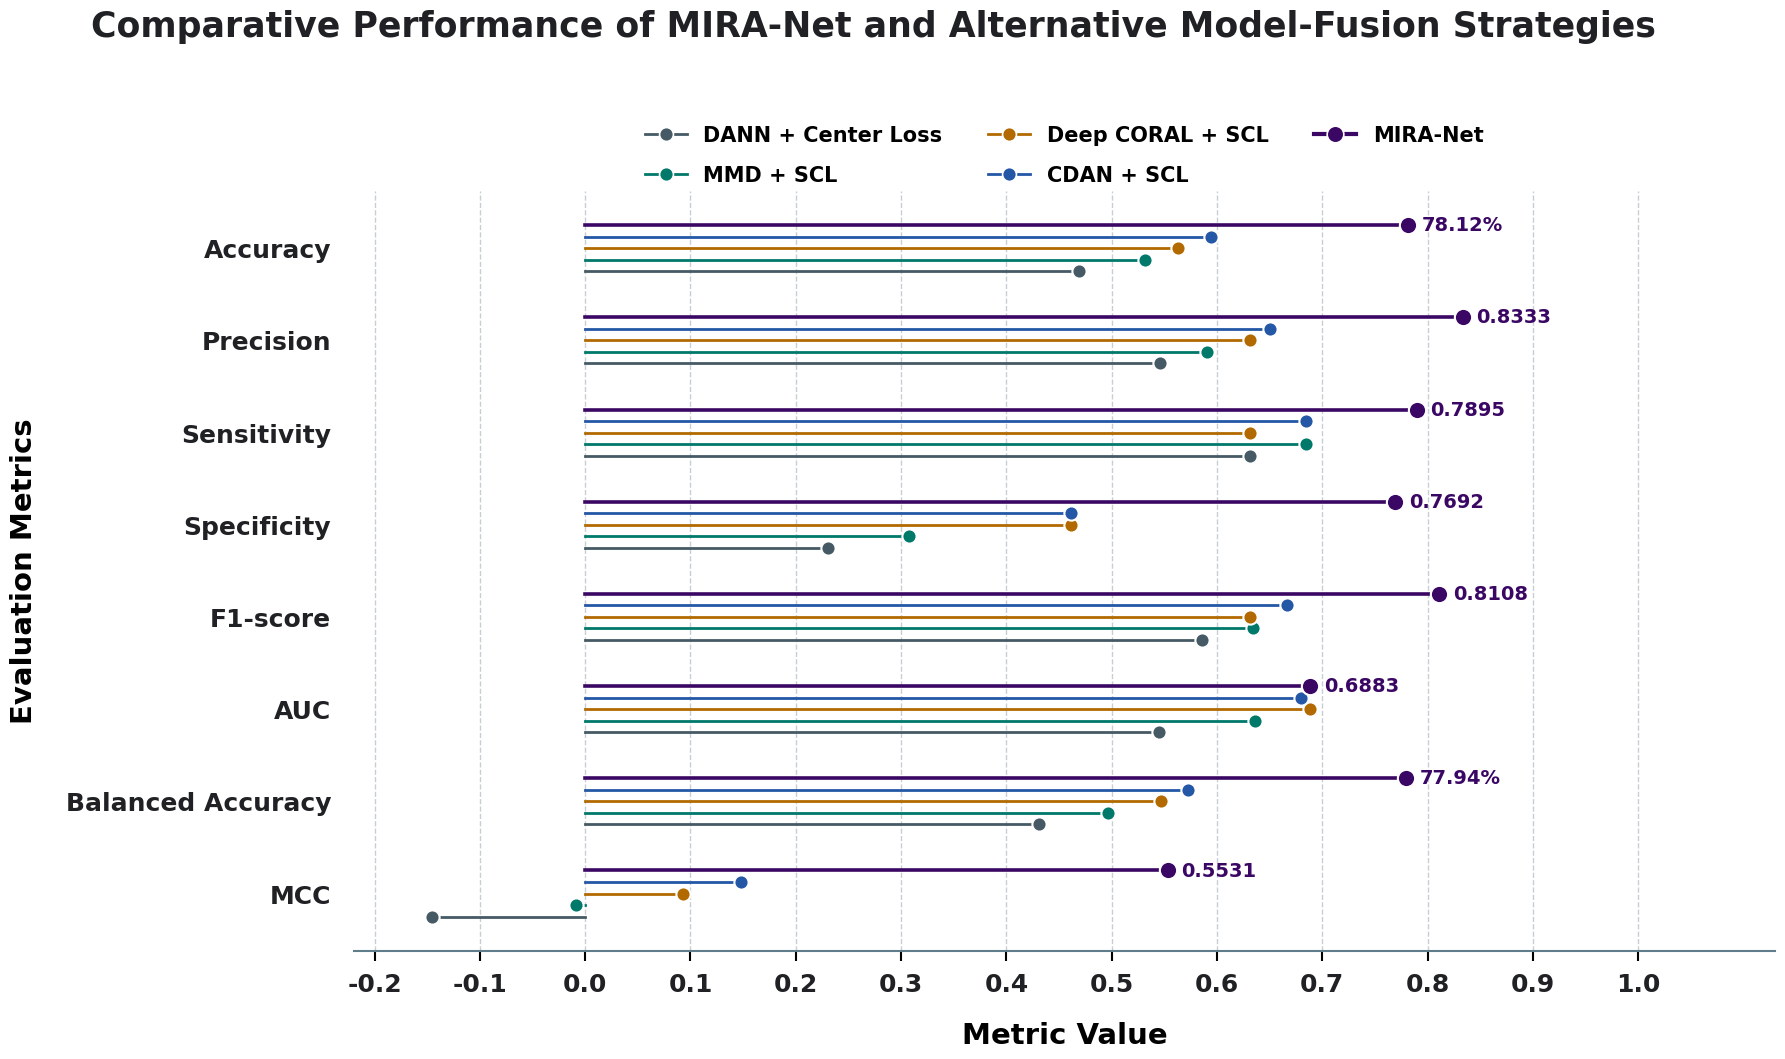

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# SINGLE-PANEL CLEVELAND DOT PLOT
# Comparative Evaluation of MIRA-Net and Alternative
# Model-Fusion Strategies | Eight Metrics
# ============================================================

# ------------------------------------------------------------
# 1. MODEL CONFIGURATIONS
# ------------------------------------------------------------

models = [
    "DANN + Center Loss",
    "MMD + SCL",
    "Deep CORAL + SCL",
    "CDAN + SCL",
    "MIRA-Net"
]

# ------------------------------------------------------------
# 2. PERFORMANCE VALUES FROM TABLE 19
# ------------------------------------------------------------

results = {
    "Accuracy": [46.88, 53.12, 56.25, 59.38, 78.12],
    "Precision": [0.5455, 0.5909, 0.6316, 0.6500, 0.8333],
    "Sensitivity": [0.6316, 0.6842, 0.6316, 0.6842, 0.7895],
    "Specificity": [0.2308, 0.3077, 0.4615, 0.4615, 0.7692],
    "F1-score": [0.5854, 0.6341, 0.6316, 0.6667, 0.8108],
    "AUC": [0.5446, 0.6356, 0.6882, 0.6802, 0.6883],
    "Balanced Accuracy": [43.12, 49.60, 54.66, 57.29, 77.94],
    "MCC": [-0.1459, -0.0086, 0.0931, 0.1479, 0.5531]
}

metric_names = list(results.keys())

# ------------------------------------------------------------
# 3. PREPARE ACTUAL METRIC VALUES
# ------------------------------------------------------------

# Convert percentage metrics to decimals for plotting.
# Values are not min-max normalized.
plot_results = {}

for metric, values in results.items():
    values = np.asarray(values, dtype=float)

    if metric in ["Accuracy", "Balanced Accuracy"]:
        values = values / 100.0

    plot_results[metric] = values

# ------------------------------------------------------------
# 4. VISUAL SETTINGS
# ------------------------------------------------------------

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 15

# Distinct, dark colors for each model
model_colors = [
    "#455A64",  # DANN + Center Loss
    "#00796B",  # MMD + SCL
    "#B26A00",  # Deep CORAL + SCL
    "#2457A6",  # CDAN + SCL
    "#3B0764"   # MIRA-Net: dark purple
]

mira_color = "#3B0764"

fig, ax = plt.subplots(figsize=(19, 12))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Metric positions
y_positions = np.arange(len(metric_names))[::-1]

# Vertical offsets separate model markers within each metric
vertical_offsets = np.linspace(-0.25, 0.25, len(models))

# ------------------------------------------------------------
# 5. PLOT ALL MODELS
# ------------------------------------------------------------

for model_idx, model in enumerate(models):

    color = model_colors[model_idx]
    is_mira = model == "MIRA-Net"

    for metric_idx, metric in enumerate(metric_names):

        x_value = plot_results[metric][model_idx]
        y_value = y_positions[metric_idx] + vertical_offsets[model_idx]

        # Horizontal line from zero to the actual metric value
        ax.plot(
            [0, x_value],
            [y_value, y_value],
            color=color,
            linewidth=2.6 if is_mira else 2.0,
            alpha=1.0,
            zorder=2
        )

        # Circular markers for every model
        ax.scatter(
            x_value,
            y_value,
            s=155 if is_mira else 105,
            color=color,
            edgecolor="white",
            linewidth=1.5,
            marker="o",
            zorder=5 if is_mira else 4
        )

        # Annotate MIRA-Net with its original values
        if is_mira:

            original_value = results[metric][model_idx]

            if metric in ["Accuracy", "Balanced Accuracy"]:
                label = f"{original_value:.2f}%"
            else:
                label = f"{original_value:.4f}"

            ax.annotate(
                label,
                xy=(x_value, y_value),
                xytext=(10, 0),
                textcoords="offset points",
                ha="left",
                va="center",
                fontsize=14,
                fontweight="bold",
                color=mira_color,
                zorder=7
            )

# ------------------------------------------------------------
# 6. AXES AND GRID
# ------------------------------------------------------------

ax.set_yticks(y_positions)

ax.set_yticklabels(
    metric_names,
    fontsize=18,
    fontweight="bold",
    color="#202124"
)

# Actual values on a shared x-axis.
# MCC includes negative values.
x_ticks = np.arange(-0.2, 1.01, 0.1)

ax.set_xlim(-0.22, 1.13)
ax.set_xticks(x_ticks)

# X-axis values: larger and bold
ax.set_xticklabels(
    [f"{x:.1f}" for x in x_ticks],
    fontsize=18,
    fontweight="bold",
    color="#202124"
)

ax.set_xlabel(
    "Metric Value",
    fontsize=21,
    fontweight="bold",
    labelpad=18
)

ax.set_ylabel(
    "Evaluation Metrics",
    fontsize=21,
    fontweight="bold",
    labelpad=20
)

ax.tick_params(
    axis="x",
    labelsize=18,
    length=7,
    width=1.5,
    pad=8
)

ax.tick_params(
    axis="y",
    labelsize=18,
    length=0,
    pad=16
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=1.0,
    color="#AAB4BE",
    alpha=0.65
)

ax.set_axisbelow(True)

# Clean, publication-style borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#607D8B")
ax.spines["bottom"].set_linewidth(1.5)

# ------------------------------------------------------------
# 7. TITLE AND LEGEND
# ------------------------------------------------------------

fig.suptitle(
    "Comparative Performance of MIRA-Net and Alternative "
    "Model-Fusion Strategies",
    fontsize=25,
    fontweight="bold",
    color="#202124",
    y=0.94
)

legend_handles = []

for idx, model in enumerate(models):

    legend_handles.append(
        Line2D(
            [0], [0],
            marker="o",
            color=model_colors[idx],
            markerfacecolor=model_colors[idx],
            markeredgecolor="white",
            markeredgewidth=1.2,
            markersize=12 if model == "MIRA-Net" else 10,
            linewidth=3.0 if model == "MIRA-Net" else 2.0,
            label=model
        )
    )

# Legend directly below the title
legend = ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.10),
    ncol=3,
    frameon=False,
    fontsize=15,
    handlelength=2.0,
    columnspacing=2.2,
    labelspacing=1.0,
    borderaxespad=0.1
)

# Make model names bold in the legend
for text in legend.get_texts():
    text.set_fontweight("bold")

# No bottom figure note

# Reduce excess top whitespace while preserving the plot layout
plt.tight_layout(
    rect=[0.04, 0.065, 0.98, 0.91],
    pad=0.5
)

# ------------------------------------------------------------
# 8. SAVE HIGH-RESOLUTION OUTPUTS
# ------------------------------------------------------------

plt.savefig(
    "MIRA_Net_Model_Fusion_Comparison.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "MIRA_Net_Model_Fusion_Comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [ ]:
# Download files in Google Colab
from google.colab import files

files.download("MIRA_Net_Model_Fusion_Comparison.png")
files.download("MIRA_Net_Model_Fusion_Comparison.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Table 5 Figure


Saved high-resolution figure: MIRA_Net_Accuracy_Precision_F1_Comparison.png
Saved vector figure:          MIRA_Net_Accuracy_Precision_F1_Comparison.pdf


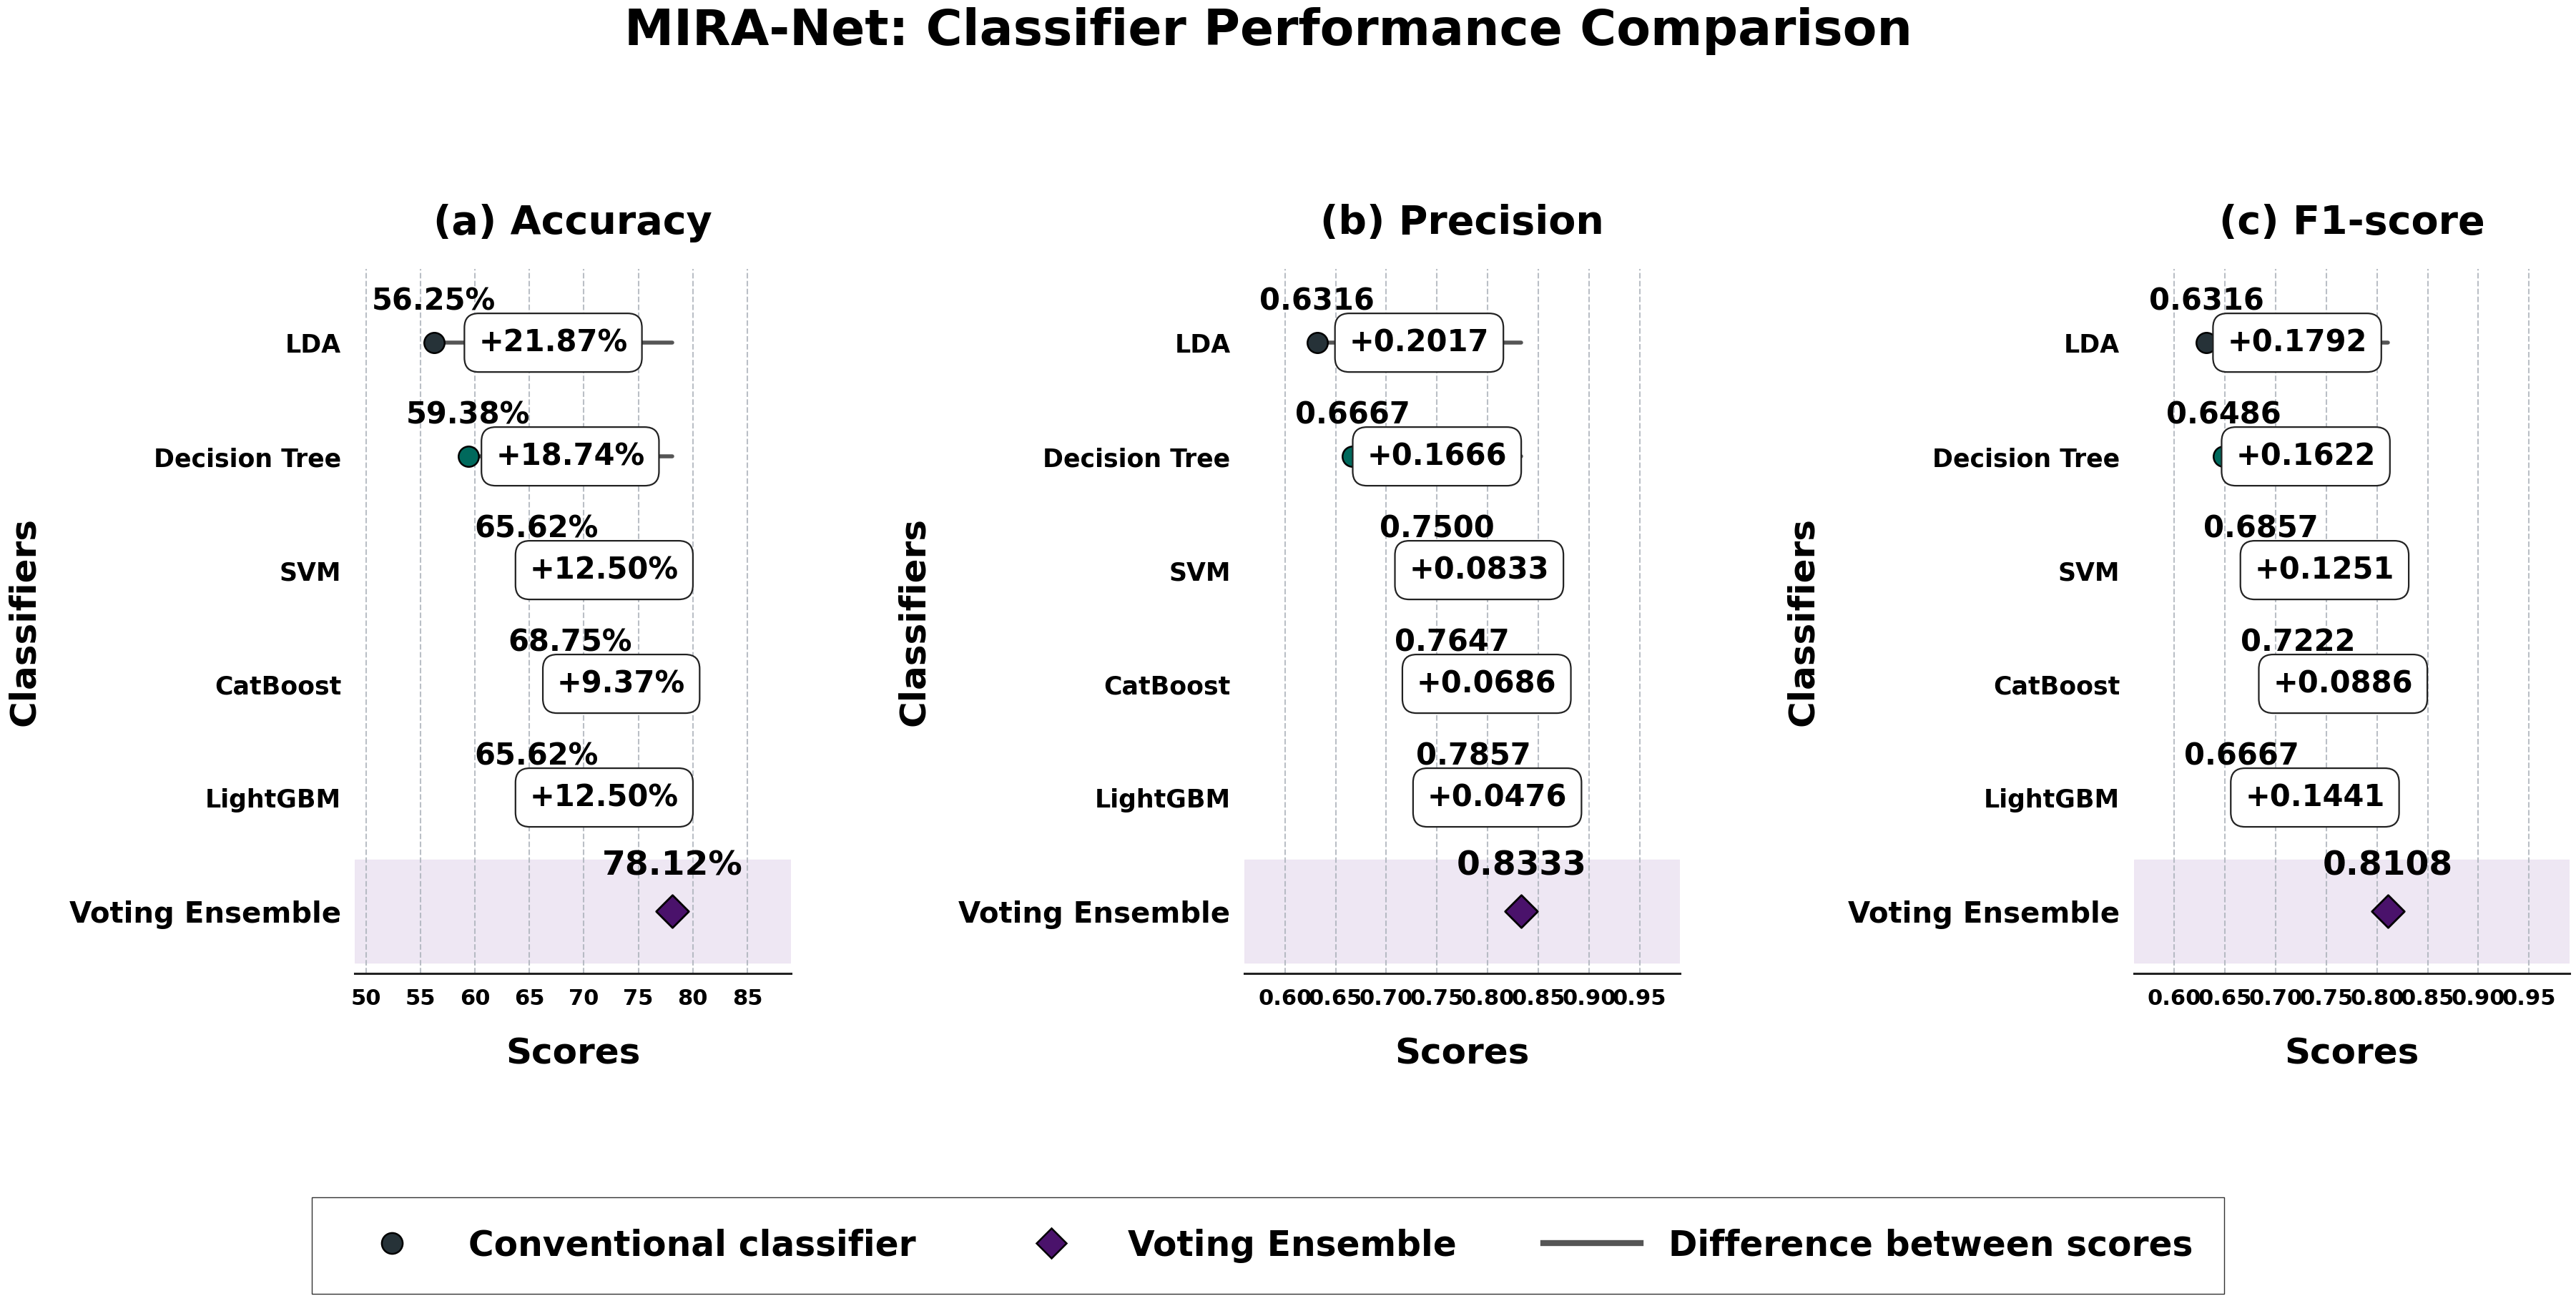


VOTING ENSEMBLE COMPARISON

Accuracy
----------------------------------------------------------------------------------------------------
LDA                Score = 56.25% | Voting Ensemble = 78.12% | Difference = +21.87%
Decision Tree      Score = 59.38% | Voting Ensemble = 78.12% | Difference = +18.74%
SVM                Score = 65.62% | Voting Ensemble = 78.12% | Difference = +12.50%
CatBoost           Score = 68.75% | Voting Ensemble = 78.12% | Difference = +9.37%
LightGBM           Score = 65.62% | Voting Ensemble = 78.12% | Difference = +12.50%
Voting Ensemble    Score = 78.12%

Precision
----------------------------------------------------------------------------------------------------
LDA                Score = 0.6316 | Voting Ensemble = 0.8333 | Difference = +0.2017
Decision Tree      Score = 0.6667 | Voting Ensemble = 0.8333 | Difference = +0.1666
SVM                Score = 0.7500 | Voting Ensemble = 0.8333 | Difference = +0.0833
CatBoost           Score = 0.7647 | Voting E

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# MIRA-Net: ACCURACY, PRECISION AND F1-SCORE COMPARISON
# Publication-quality horizontal dumbbell visualization
#
# (a) Accuracy
# (b) Precision
# (c) F1-score
#
# Circles  = Conventional classifiers
# Diamonds = Voting Ensemble
# Lines    = Difference between scores
#
# VISIBILITY IMPROVEMENTS:
# 1. Much larger, bold legend text.
# 2. Much larger, black classifier names.
# 3. Voting Ensemble label is black, bold, and extra-large.
# 4. Larger score labels and difference annotations.
# 5. Increased figure dimensions and panel spacing.
# 6. High-resolution PNG and vector PDF output.
# ============================================================


# ------------------------------------------------------------
# 1. CLASSIFIERS
# ------------------------------------------------------------

classifiers = [
    "LDA",
    "Decision Tree",
    "SVM",
    "CatBoost",
    "LightGBM",
    "Voting Ensemble"
]

baseline_classifiers = classifiers[:-1]


# ------------------------------------------------------------
# 2. EXACT VALUES FROM TABLE 20
# ------------------------------------------------------------

metrics = {
    "Accuracy": {
        "values": [56.25, 59.38, 65.62, 68.75, 65.62, 78.12],
        "decimals": 2,
        "suffix": "%",
        "limits": (49, 89),
        "ticks": np.arange(50, 90, 5),
        "panel": "(a)"
    },

    "Precision": {
        "values": [0.6316, 0.6667, 0.7500, 0.7647, 0.7857, 0.8333],
        "decimals": 4,
        "suffix": "",
        "limits": (0.56, 0.99),
        "ticks": np.arange(0.60, 0.951, 0.05),
        "panel": "(b)"
    },

    "F1-score": {
        "values": [0.6316, 0.6486, 0.6857, 0.7222, 0.6667, 0.8108],
        "decimals": 4,
        "suffix": "",
        "limits": (0.56, 0.99),
        "ticks": np.arange(0.60, 0.951, 0.05),
        "panel": "(c)"
    }
}


# ------------------------------------------------------------
# 3. COLORS
# ------------------------------------------------------------

classifier_colors = {
    "LDA": "#263238",
    "Decision Tree": "#00695C",
    "SVM": "#A84300",
    "CatBoost": "#174A8B",
    "LightGBM": "#63358C"
}

ensemble_color = "#4A126B"
connector_color = "#555555"

text_color = "#000000"
grid_color = "#AEB4BC"
ensemble_band_color = "#EEE6F3"


# ------------------------------------------------------------
# 4. GLOBAL TYPOGRAPHY
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 28,
    "font.weight": "bold",

    "axes.labelsize": 34,
    "axes.labelweight": "bold",

    "axes.titlesize": 38,
    "axes.titleweight": "bold",

    "xtick.labelsize": 26,
    "ytick.labelsize": 28,

    "text.color": "#000000",
    "axes.labelcolor": "#000000",
    "xtick.color": "#000000",
    "ytick.color": "#000000",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    "savefig.dpi": 600
})


# ------------------------------------------------------------
# 5. CREATE THREE LARGE SIDE-BY-SIDE PANELS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(38, 19),
    facecolor="white"
)

y_positions = np.arange(len(classifiers))


# ------------------------------------------------------------
# 6. DRAW EACH METRIC
# ------------------------------------------------------------

for ax, (metric_name, data) in zip(axes, metrics.items()):

    values = np.asarray(data["values"], dtype=float)

    baseline_values = values[:-1]
    ensemble_value = values[-1]
    ensemble_y = len(classifiers) - 1

    decimals = data["decimals"]
    suffix = data["suffix"]

    ax.set_facecolor("white")

    # --------------------------------------------------------
    # Highlight Voting Ensemble row
    # --------------------------------------------------------

    ax.axhspan(
        ensemble_y - 0.45,
        ensemble_y + 0.45,
        color=ensemble_band_color,
        alpha=0.95,
        zorder=0
    )

    # --------------------------------------------------------
    # Conventional classifier comparisons
    # --------------------------------------------------------

    for i, (classifier, baseline_value) in enumerate(
        zip(baseline_classifiers, baseline_values)
    ):

        # Connecting line
        ax.plot(
            [baseline_value, ensemble_value],
            [i, i],
            color=connector_color,
            linewidth=4.0,
            solid_capstyle="round",
            zorder=1
        )

        # Conventional classifier circle
        ax.scatter(
            baseline_value,
            i,
            s=420,
            marker="o",
            color=classifier_colors[classifier],
            edgecolor="black",
            linewidth=1.8,
            zorder=4
        )

        # Score label: larger, black and bold
        baseline_label = f"{baseline_value:.{decimals}f}{suffix}"

        ax.annotate(
            baseline_label,
            xy=(baseline_value, i),
            xytext=(0, 27),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=30,
            fontweight="bold",
            color="black",
            annotation_clip=False,
            zorder=10
        )

        # Difference from Voting Ensemble
        difference = ensemble_value - baseline_value

        difference_label = (
            f"+{difference:.{decimals}f}{suffix}"
            if difference >= 0
            else f"{difference:.{decimals}f}{suffix}"
        )

        midpoint = (baseline_value + ensemble_value) / 2

        ax.annotate(
            difference_label,
            xy=(midpoint, i),
            xytext=(0, 0),
            textcoords="offset points",
            ha="center",
            va="center",
            fontsize=30,
            fontweight="bold",
            color="black",
            bbox=dict(
                boxstyle="round,pad=0.48",
                facecolor="white",
                edgecolor="#222222",
                linewidth=1.6,
                alpha=1.0
            ),
            zorder=8
        )

    # --------------------------------------------------------
    # Voting Ensemble diamond
    # --------------------------------------------------------

    ax.scatter(
        ensemble_value,
        ensemble_y,
        s=540,
        marker="D",
        color=ensemble_color,
        edgecolor="black",
        linewidth=2.0,
        zorder=7
    )

    # Voting Ensemble score: extra-large, bold and black
    ensemble_label = f"{ensemble_value:.{decimals}f}{suffix}"

    ax.annotate(
        ensemble_label,
        xy=(ensemble_value, ensemble_y),
        xytext=(0, 30),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=34,
        fontweight="bold",
        color="black",
        annotation_clip=False,
        zorder=10
    )

    # --------------------------------------------------------
    # PANEL TITLE
    # --------------------------------------------------------

    ax.set_title(
        f"{data['panel']} {metric_name}",
        fontsize=40,
        fontweight="bold",
        color="black",
        pad=36
    )

    # --------------------------------------------------------
    # CLASSIFIER NAMES
    # All classifier labels are black and bold.
    # Voting Ensemble receives extra emphasis.
    # --------------------------------------------------------

    ax.set_yticks(y_positions)

    ax.set_yticklabels(
        classifiers,
        fontsize=30,
        fontweight="bold",
        color="black"
    )

    for label in ax.get_yticklabels():

        label.set_color("black")
        label.set_fontweight("bold")
        label.set_fontsize(30)

        if label.get_text() == "Voting Ensemble":
            label.set_color("black")
            label.set_fontweight("bold")
            label.set_fontsize(34)

    # --------------------------------------------------------
    # SCORE SCALE
    # --------------------------------------------------------

    ax.set_xlim(*data["limits"])
    ax.set_xticks(data["ticks"])

    # --------------------------------------------------------
    # AXIS TITLES
    # Horizontal axis = Scores
    # Vertical axis = Classifiers
    # --------------------------------------------------------

    ax.set_xlabel(
        "Scores",
        fontsize=36,
        fontweight="bold",
        color="black",
        labelpad=28
    )

    ax.set_ylabel(
        "Classifiers",
        fontsize=36,
        fontweight="bold",
        color="black",
        labelpad=28
    )

    # --------------------------------------------------------
    # TICK SETTINGS
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        length=0,
        pad=14
    )

    for label in ax.get_xticklabels():
        label.set_fontsize(22)
        label.set_fontweight("bold")
        label.set_color("black")

    for label in ax.get_yticklabels():
        if label.get_text() == "Voting Ensemble":
            label.set_fontsize(29)
        else:
            label.set_fontsize(25)

        label.set_fontweight("bold")
        label.set_color("black")

    # --------------------------------------------------------
    # GRID AND AXES STYLING
    # --------------------------------------------------------

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=1.5,
        color=grid_color,
        alpha=0.85
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.spines["bottom"].set_color("#222222")
    ax.spines["bottom"].set_linewidth(2.2)

    # Preserve original classifier row arrangement
    ax.set_ylim(len(classifiers) - 0.45, -0.65)


# ------------------------------------------------------------
# 7. EXTRA-LARGE MAIN TITLE
# ------------------------------------------------------------

fig.suptitle(
    "MIRA-Net: Classifier Performance Comparison",
    fontsize=50,
    fontweight="bold",
    color="black",
    y=0.975
)


# ------------------------------------------------------------
# 8. EXTRA-LARGE LEGEND
# ------------------------------------------------------------

legend_handles = [

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=21,
        markerfacecolor="#263238",
        markeredgecolor="black",
        markeredgewidth=1.8,
        label="Conventional classifier"
    ),

    Line2D(
        [0], [0],
        marker="D",
        linestyle="None",
        markersize=21,
        markerfacecolor=ensemble_color,
        markeredgecolor="black",
        markeredgewidth=1.8,
        label="Voting Ensemble"
    ),

    Line2D(
        [0], [0],
        color=connector_color,
        linewidth=6,
        label="Difference between scores"
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    frameon=True,
    fancybox=False,
    framealpha=1.0,
    edgecolor="#333333",
    facecolor="white",
    prop={
        "weight": "bold",
        "size": 35
    },
    bbox_to_anchor=(0.5, 0.015),
    handlelength=2.8,
    handletextpad=0.8,
    columnspacing=2.5,
    borderpad=0.9,
    labelcolor="black"
)


# ------------------------------------------------------------
# 9. LAYOUT
# Reserve space for title and large legend.
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0.025, 0.17, 0.99, 0.91],
    w_pad=3.8
)


# ------------------------------------------------------------
# 10. SAVE PUBLICATION-QUALITY FIGURES
# ------------------------------------------------------------

png_filename = "MIRA_Net_Accuracy_Precision_F1_Comparison.png"
pdf_filename = "MIRA_Net_Accuracy_Precision_F1_Comparison.pdf"

plt.savefig(
    png_filename,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    pdf_filename,
    bbox_inches="tight",
    facecolor="white"
)

print(f"\nSaved high-resolution figure: {png_filename}")
print(f"Saved vector figure:          {pdf_filename}")


# ------------------------------------------------------------
# 11. DISPLAY FIGURE
# ------------------------------------------------------------

plt.show()


# ------------------------------------------------------------
# 12. PRINT NUMERICAL COMPARISONS
# ------------------------------------------------------------

print("\nVOTING ENSEMBLE COMPARISON")
print("=" * 100)

for metric_name, data in metrics.items():

    values = data["values"]
    ensemble_value = values[-1]
    decimals = data["decimals"]
    suffix = data["suffix"]

    print(f"\n{metric_name}")
    print("-" * 100)

    for classifier, baseline_value in zip(
        baseline_classifiers,
        values[:-1]
    ):

        difference = ensemble_value - baseline_value

        difference_label = (
            f"+{difference:.{decimals}f}{suffix}"
            if difference >= 0
            else f"{difference:.{decimals}f}{suffix}"
        )

        print(
            f"{classifier:<18}"
            f" Score = {baseline_value:.{decimals}f}{suffix}"
            f" | Voting Ensemble = "
            f"{ensemble_value:.{decimals}f}{suffix}"
            f" | Difference = {difference_label}"
        )

    print(
        f"{'Voting Ensemble':<18}"
        f" Score = {ensemble_value:.{decimals}f}{suffix}"
    )


In [ ]:
# Download files in Google Colab
from google.colab import files

files.download("MIRA_Net_Accuracy_Precision_F1_Comparison.png")
files.download("MIRA_Net_Accuracy_Precision_F1_Comparison.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

RF-SHAP

Acoustic

FOLD-WISE ACOUSTIC SHAP DATA
  Fold  Rank             Feature  Mean_Absolute_SHAP
Fold 1     1 Degree-voice breaks            0.020099
Fold 1     2        MDVP:Shimmer            0.019161
Fold 1     3              Delta1            0.019100
Fold 1     4                RPDE            0.018424
Fold 1     5              Delta0            0.017792
Fold 1     6 No. of voice breaks            0.017317
Fold 1     7               MFCC5            0.017233
Fold 2     1        MDVP:Shimmer            0.029120
Fold 2     2                RPDE            0.024858
Fold 2     3             Delta11            0.021526
Fold 2     4              Delta3            0.021401
Fold 2     5 Degree-voice breaks            0.019076
Fold 2     6               MFCC5            0.015631
Fold 2     7               MFCC7            0.014959
Fold 3     1 Degree-voice breaks            0.027577
Fold 3     2                 PPE            0.022081
Fold 3     3              Delta0            0.021273
Fold 3     4     

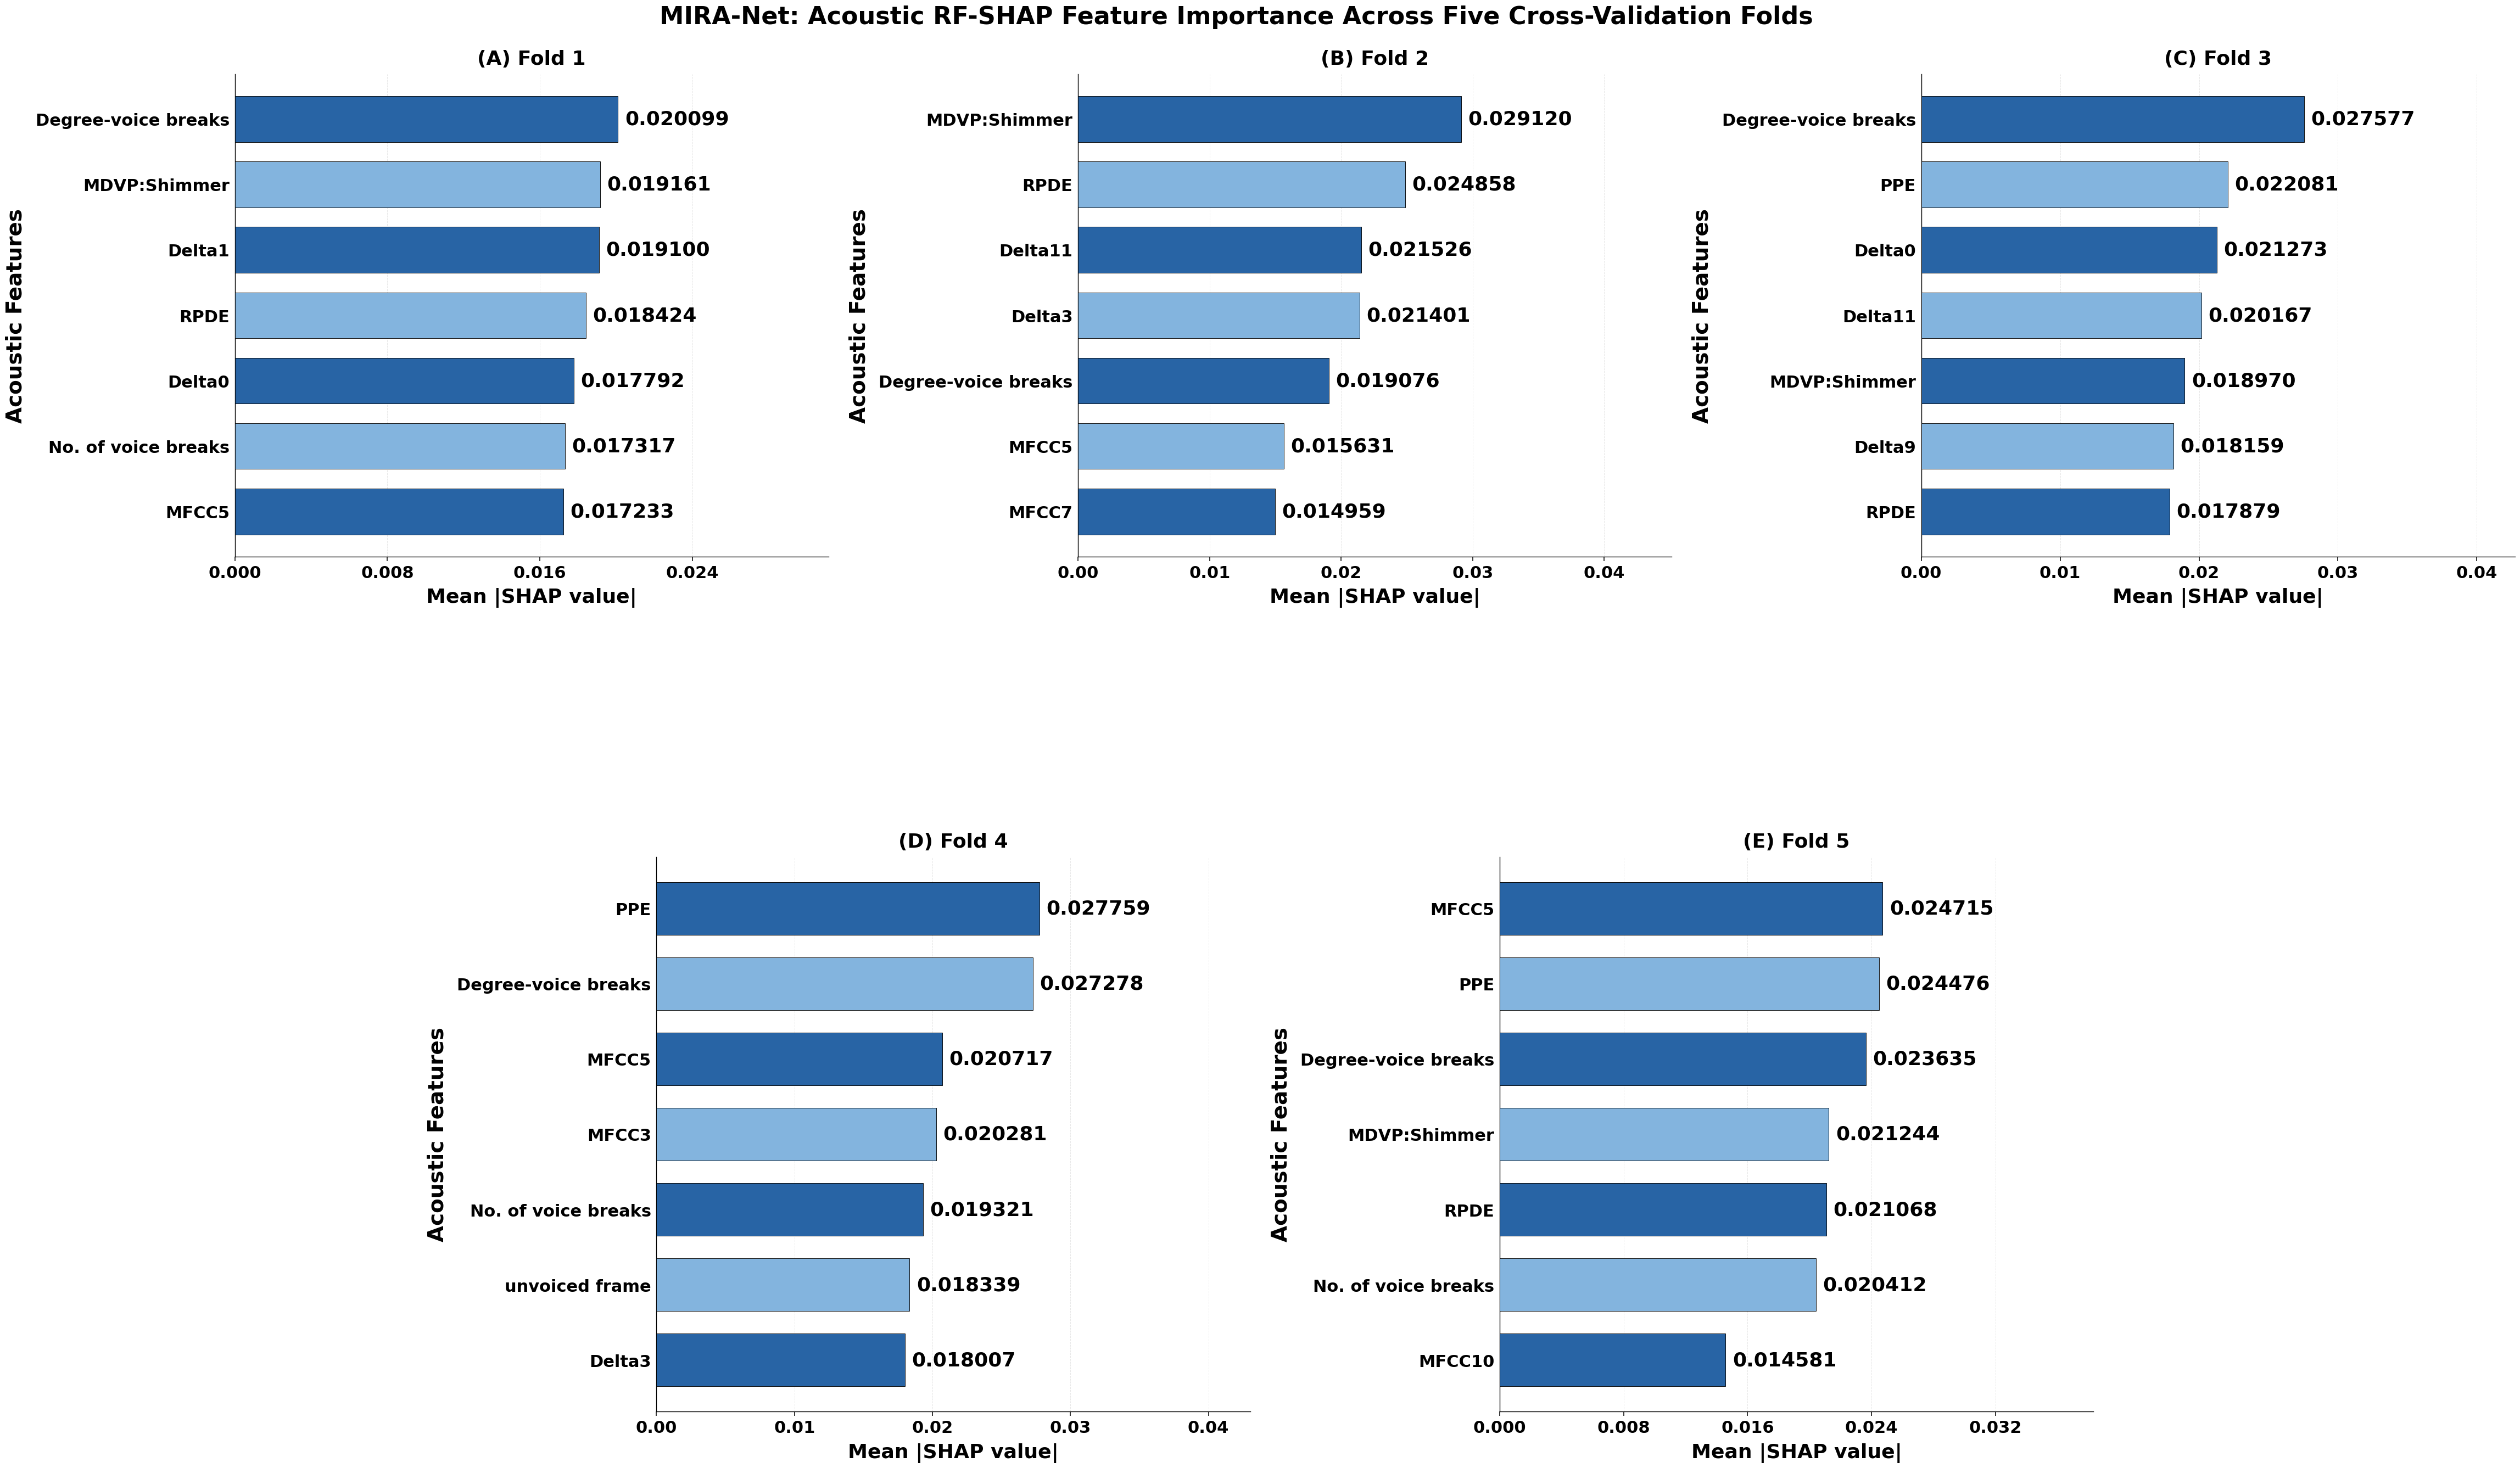


Completed successfully.


In [6]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import MaxNLocator

# ============================================================
# MIRA-Net: ACOUSTIC RF-SHAP FEATURE IMPORTANCE
#
# OUTPUTS:
# 1. One combined five-panel figure (PNG + PDF)
# 2. CSV containing fold-wise SHAP values
# 3. CSV containing feature-selection frequency
#
# Layout:
#   First row:  A, B, C
#   Second row: D, E (centred)
#
# No individual fold figures.
# No feature-selection frequency panel.
#
# Original font sizes and SHAP values are preserved.
# Larger canvas and spacing are used to reduce overlap.
# ============================================================


# ============================================================
# 1. CONFIGURATION
# ============================================================

OUTPUT_DIR = "MIRA_Net_Acoustic_SHAP_Visualizations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DPI = 600

COLOR_PRIMARY = "#2864A5"
COLOR_SECONDARY = "#83B4DE"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": DPI,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})


# ============================================================
# 2. EXACT FOLD-WISE TOP-7 ACOUSTIC FEATURES AND SHAP VALUES
# ============================================================

fold_data = {
    "Fold 1": {
        "features": [
            "Degree-voice breaks",
            "MDVP:Shimmer",
            "Delta1",
            "RPDE",
            "Delta0",
            "No. of voice breaks",
            "MFCC5"
        ],
        "shap": [
            0.020099,
            0.019161,
            0.019100,
            0.018424,
            0.017792,
            0.017317,
            0.017233
        ]
    },

    "Fold 2": {
        "features": [
            "MDVP:Shimmer",
            "RPDE",
            "Delta11",
            "Delta3",
            "Degree-voice breaks",
            "MFCC5",
            "MFCC7"
        ],
        "shap": [
            0.029120,
            0.024858,
            0.021526,
            0.021401,
            0.019076,
            0.015631,
            0.014959
        ]
    },

    "Fold 3": {
        "features": [
            "Degree-voice breaks",
            "PPE",
            "Delta0",
            "Delta11",
            "MDVP:Shimmer",
            "Delta9",
            "RPDE"
        ],
        "shap": [
            0.027577,
            0.022081,
            0.021273,
            0.020167,
            0.018970,
            0.018159,
            0.017879
        ]
    },

    "Fold 4": {
        "features": [
            "PPE",
            "Degree-voice breaks",
            "MFCC5",
            "MFCC3",
            "No. of voice breaks",
            "unvoiced frame",
            "Delta3"
        ],
        "shap": [
            0.027759,
            0.027278,
            0.020717,
            0.020281,
            0.019321,
            0.018339,
            0.018007
        ]
    },

    "Fold 5": {
        "features": [
            "MFCC5",
            "PPE",
            "Degree-voice breaks",
            "MDVP:Shimmer",
            "RPDE",
            "No. of voice breaks",
            "MFCC10"
        ],
        "shap": [
            0.024715,
            0.024476,
            0.023635,
            0.021244,
            0.021068,
            0.020412,
            0.014581
        ]
    }
}


# ============================================================
# 3. EXPORT FOLD-WISE SHAP DATA TO CSV
# ============================================================

records = []

for fold_name, data in fold_data.items():
    for rank, (feature, shap_value) in enumerate(
        zip(data["features"], data["shap"]), start=1
    ):
        records.append({
            "Fold": fold_name,
            "Rank": rank,
            "Feature": feature,
            "Mean_Absolute_SHAP": shap_value
        })

fold_df = pd.DataFrame(records)

fold_csv_path = os.path.join(
    OUTPUT_DIR,
    "Acoustic_RF_SHAP_Foldwise_Data.csv"
)

fold_df.to_csv(fold_csv_path, index=False)

print("=" * 70)
print("FOLD-WISE ACOUSTIC SHAP DATA")
print("=" * 70)
print(fold_df.to_string(index=False))

print("\nTotal fold-wise selections:", len(fold_df))
print("Expected selections: 35")
print("Actual selections:", len(fold_df))

assert len(fold_df) == 35, (
    "Expected 7 feature selections in each of 5 folds."
)

print("\nFold-wise SHAP data saved:")
print(os.path.abspath(fold_csv_path))


# ============================================================
# 4. CALCULATE FEATURE-SELECTION FREQUENCY
# Retained for CSV export only.
# ============================================================

all_features = sorted({
    feature
    for data in fold_data.values()
    for feature in data["features"]
})

frequency_records = []

for feature in all_features:
    selected_folds = [
        fold_name
        for fold_name, data in fold_data.items()
        if feature in data["features"]
    ]

    frequency_records.append({
        "Feature": feature,
        "Selection_Frequency": len(selected_folds),
        "Percentage_of_Folds": (
            len(selected_folds) / len(fold_data)
        ) * 100,
        "Selected_Folds": ", ".join(selected_folds)
    })

frequency_df = pd.DataFrame(frequency_records)

frequency_df = frequency_df.sort_values(
    by=["Selection_Frequency", "Feature"],
    ascending=[False, True]
).reset_index(drop=True)

frequency_csv_path = os.path.join(
    OUTPUT_DIR,
    "Acoustic_Feature_Selection_Frequency.csv"
)

frequency_df.to_csv(frequency_csv_path, index=False)

print("\nFeature-selection frequency:")
print(frequency_df.to_string(index=False))

print("\nFrequency data saved:")
print(os.path.abspath(frequency_csv_path))


# ============================================================
# 5. HELPER FUNCTION: STYLE AXES
# Font sizes preserved exactly as in the supplied code.
# ============================================================

def style_axes(ax):

    ax.tick_params(
        axis="x",
        labelsize=22,
        width=1.1,
        length=6,
        colors="black",
        pad=5
    )

    ax.tick_params(
        axis="y",
        labelsize=22,
        width=1.0,
        length=0,
        colors="black",
        pad=7
    )

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.7,
        alpha=0.30,
        zorder=0
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)


# ============================================================
# 6. HELPER FUNCTION: DRAW SHAP BAR CHARTS
# Font sizes preserved; annotation room increased.
# ============================================================

def draw_shap_bars(ax, features, shap_values, title):

    features = list(features)
    shap_values = np.asarray(shap_values, dtype=float)

    # Sort ascending so the largest bar appears at the top
    order = np.argsort(shap_values)

    sorted_features = [features[i] for i in order]
    sorted_values = shap_values[order]

    colors = [
        COLOR_PRIMARY if i % 2 == 0 else COLOR_SECONDARY
        for i in range(len(sorted_features))
    ]

    y_positions = np.arange(len(sorted_features))

    bars = ax.barh(
        y_positions,
        sorted_values,
        color=colors,
        edgecolor="black",
        linewidth=0.65,
        height=0.70,
        zorder=3
    )

    ax.set_yticks(y_positions)

    ax.set_yticklabels(
        sorted_features,
        fontsize=12,
        fontweight="bold",
        color="black"
    )

    max_value = float(np.max(sorted_values))

    # Increased right-side space for numeric annotations
    ax.set_xlim(0, max_value * 1.55)

    # SHAP importance annotations: original font size preserved
    for bar, value in zip(bars, sorted_values):

        ax.text(
            value + max_value * 0.018,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.6f}",
            va="center",
            ha="left",
            fontsize=26,
            fontweight="bold",
            color="black",
            clip_on=False
        )

    ax.set_title(
        title,
        fontsize=26,
        fontweight="bold",
        color="black",
        pad=13
    )

    ax.set_xlabel(
        "Mean |SHAP value|",
        fontsize=26,
        fontweight="bold",
        color="black",
        labelpad=9
    )

    ax.set_ylabel(
        "Acoustic Features",
        fontsize=28,
        fontweight="black",
        color="black",
        labelpad=12
    )

    ax.tick_params(
        axis="x",
        labelsize=22
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))

    style_axes(ax)

    return ax


# ============================================================
# 7. CREATE THE FIVE-PANEL FIGURE
#
# Top row:    A, B, C
# Bottom row: D, E (centred)
#
# Larger canvas and increased spacing help avoid overlap.
# ============================================================

fig = plt.figure(figsize=(48, 28))

gs = gridspec.GridSpec(
    nrows=2,
    ncols=6,
    figure=fig,
    height_ratios=[1, 1.15],
    hspace=0.58,
    wspace=1.45
)

# PANEL A: FOLD 1
ax1 = fig.add_subplot(gs[0, 0:2])

draw_shap_bars(
    ax1,
    fold_data["Fold 1"]["features"],
    fold_data["Fold 1"]["shap"],
    "(A) Fold 1"
)

# PANEL B: FOLD 2
ax2 = fig.add_subplot(gs[0, 2:4])

draw_shap_bars(
    ax2,
    fold_data["Fold 2"]["features"],
    fold_data["Fold 2"]["shap"],
    "(B) Fold 2"
)

# PANEL C: FOLD 3
ax3 = fig.add_subplot(gs[0, 4:6])

draw_shap_bars(
    ax3,
    fold_data["Fold 3"]["features"],
    fold_data["Fold 3"]["shap"],
    "(C) Fold 3"
)

# PANEL D: FOLD 4 — centred bottom row
ax4 = fig.add_subplot(gs[1, 1:3])

draw_shap_bars(
    ax4,
    fold_data["Fold 4"]["features"],
    fold_data["Fold 4"]["shap"],
    "(D) Fold 4"
)

# PANEL E: FOLD 5 — centred bottom row
ax5 = fig.add_subplot(gs[1, 3:5])

draw_shap_bars(
    ax5,
    fold_data["Fold 5"]["features"],
    fold_data["Fold 5"]["shap"],
    "(E) Fold 5"
)


# ============================================================
# 8. OVERALL FIGURE TITLE
# Original font size preserved.
# ============================================================

fig.suptitle(
    "MIRA-Net: Acoustic RF-SHAP Feature Importance "
    "Across Five Cross-Validation Folds",
    fontsize=32,
    fontweight="bold",
    color="black",
    y=0.985
)


# ============================================================
# 9. FINAL LAYOUT ADJUSTMENTS
# ============================================================

fig.subplots_adjust(
    left=0.12,
    right=0.985,
    top=0.94,
    bottom=0.07,
    hspace=0.58,
    wspace=1.45
)


# ============================================================
# 10. SAVE COMBINED FIGURE
# ============================================================

combined_png = os.path.join(
    OUTPUT_DIR,
    "Acoustic_SHAP_Combined_2x3_Large.png"
)

combined_pdf = os.path.join(
    OUTPUT_DIR,
    "Acoustic_SHAP_Combined_2x3_Large.pdf"
)

# High-resolution PNG
fig.savefig(
    combined_png,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.20
)

# Vector PDF
fig.savefig(
    combined_pdf,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.20
)

print("\n" + "=" * 70)
print("MIRA-Net COMBINED ACOUSTIC SHAP FIGURE GENERATED")
print("=" * 70)

print("\nCombined PNG:")
print(os.path.abspath(combined_png))

print("\nCombined PDF:")
print(os.path.abspath(combined_pdf))

print("\nCSV data files:")
print(os.path.abspath(fold_csv_path))
print(os.path.abspath(frequency_csv_path))

print("\nOutput directory:")
print(os.path.abspath(OUTPUT_DIR))

# Display the combined figure only
plt.show()
plt.close(fig)

print("\nCompleted successfully.")


In [7]:
from google.colab import files
import os

# Output directory created by your MIRA-Net code
OUTPUT_DIR = "MIRA_Net_Acoustic_SHAP_Visualizations"

# File paths
png_path = os.path.join(
    OUTPUT_DIR,
    "Acoustic_SHAP_Combined_2x3_Large.png"
)

pdf_path = os.path.join(
    OUTPUT_DIR,
    "Acoustic_SHAP_Combined_2x3_Large.pdf"
)

# Download high-resolution PNG
files.download(png_path)

# Download publication-ready PDF
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MEG

FOLD-WISE MEG SHAP DATA
  Fold  Rank                     Feature  Mean_Absolute_SHAP
Fold 1     1             burst_rate_asym            0.019693
Fold 1     2          burst_dur_cv_R_std            0.014527
Fold 1     3          burst_dur_cv_L_std            0.013783
Fold 1     4                 ibi_cv_asym            0.013600
Fold 1     5   mean_burst_duration_R_std            0.013082
Fold 1     6              mean_ibi_R_std            0.012419
Fold 1     7    mean_burst_duration_asym            0.011698
Fold 2     1       peak_beta_freq_R_mean            0.023049
Fold 2     2       peak_beta_freq_L_mean            0.019410
Fold 2     3     beta_median_freq_R_mean            0.012586
Fold 2     4    spectral_flatness_L_mean            0.012545
Fold 2     5    spectral_flatness_R_mean            0.011357
Fold 2     6     beta_median_freq_L_mean            0.010603
Fold 2     7          burst_dur_cv_L_std            0.010242
Fold 3     1                 ibi_cv_asym            0.019851


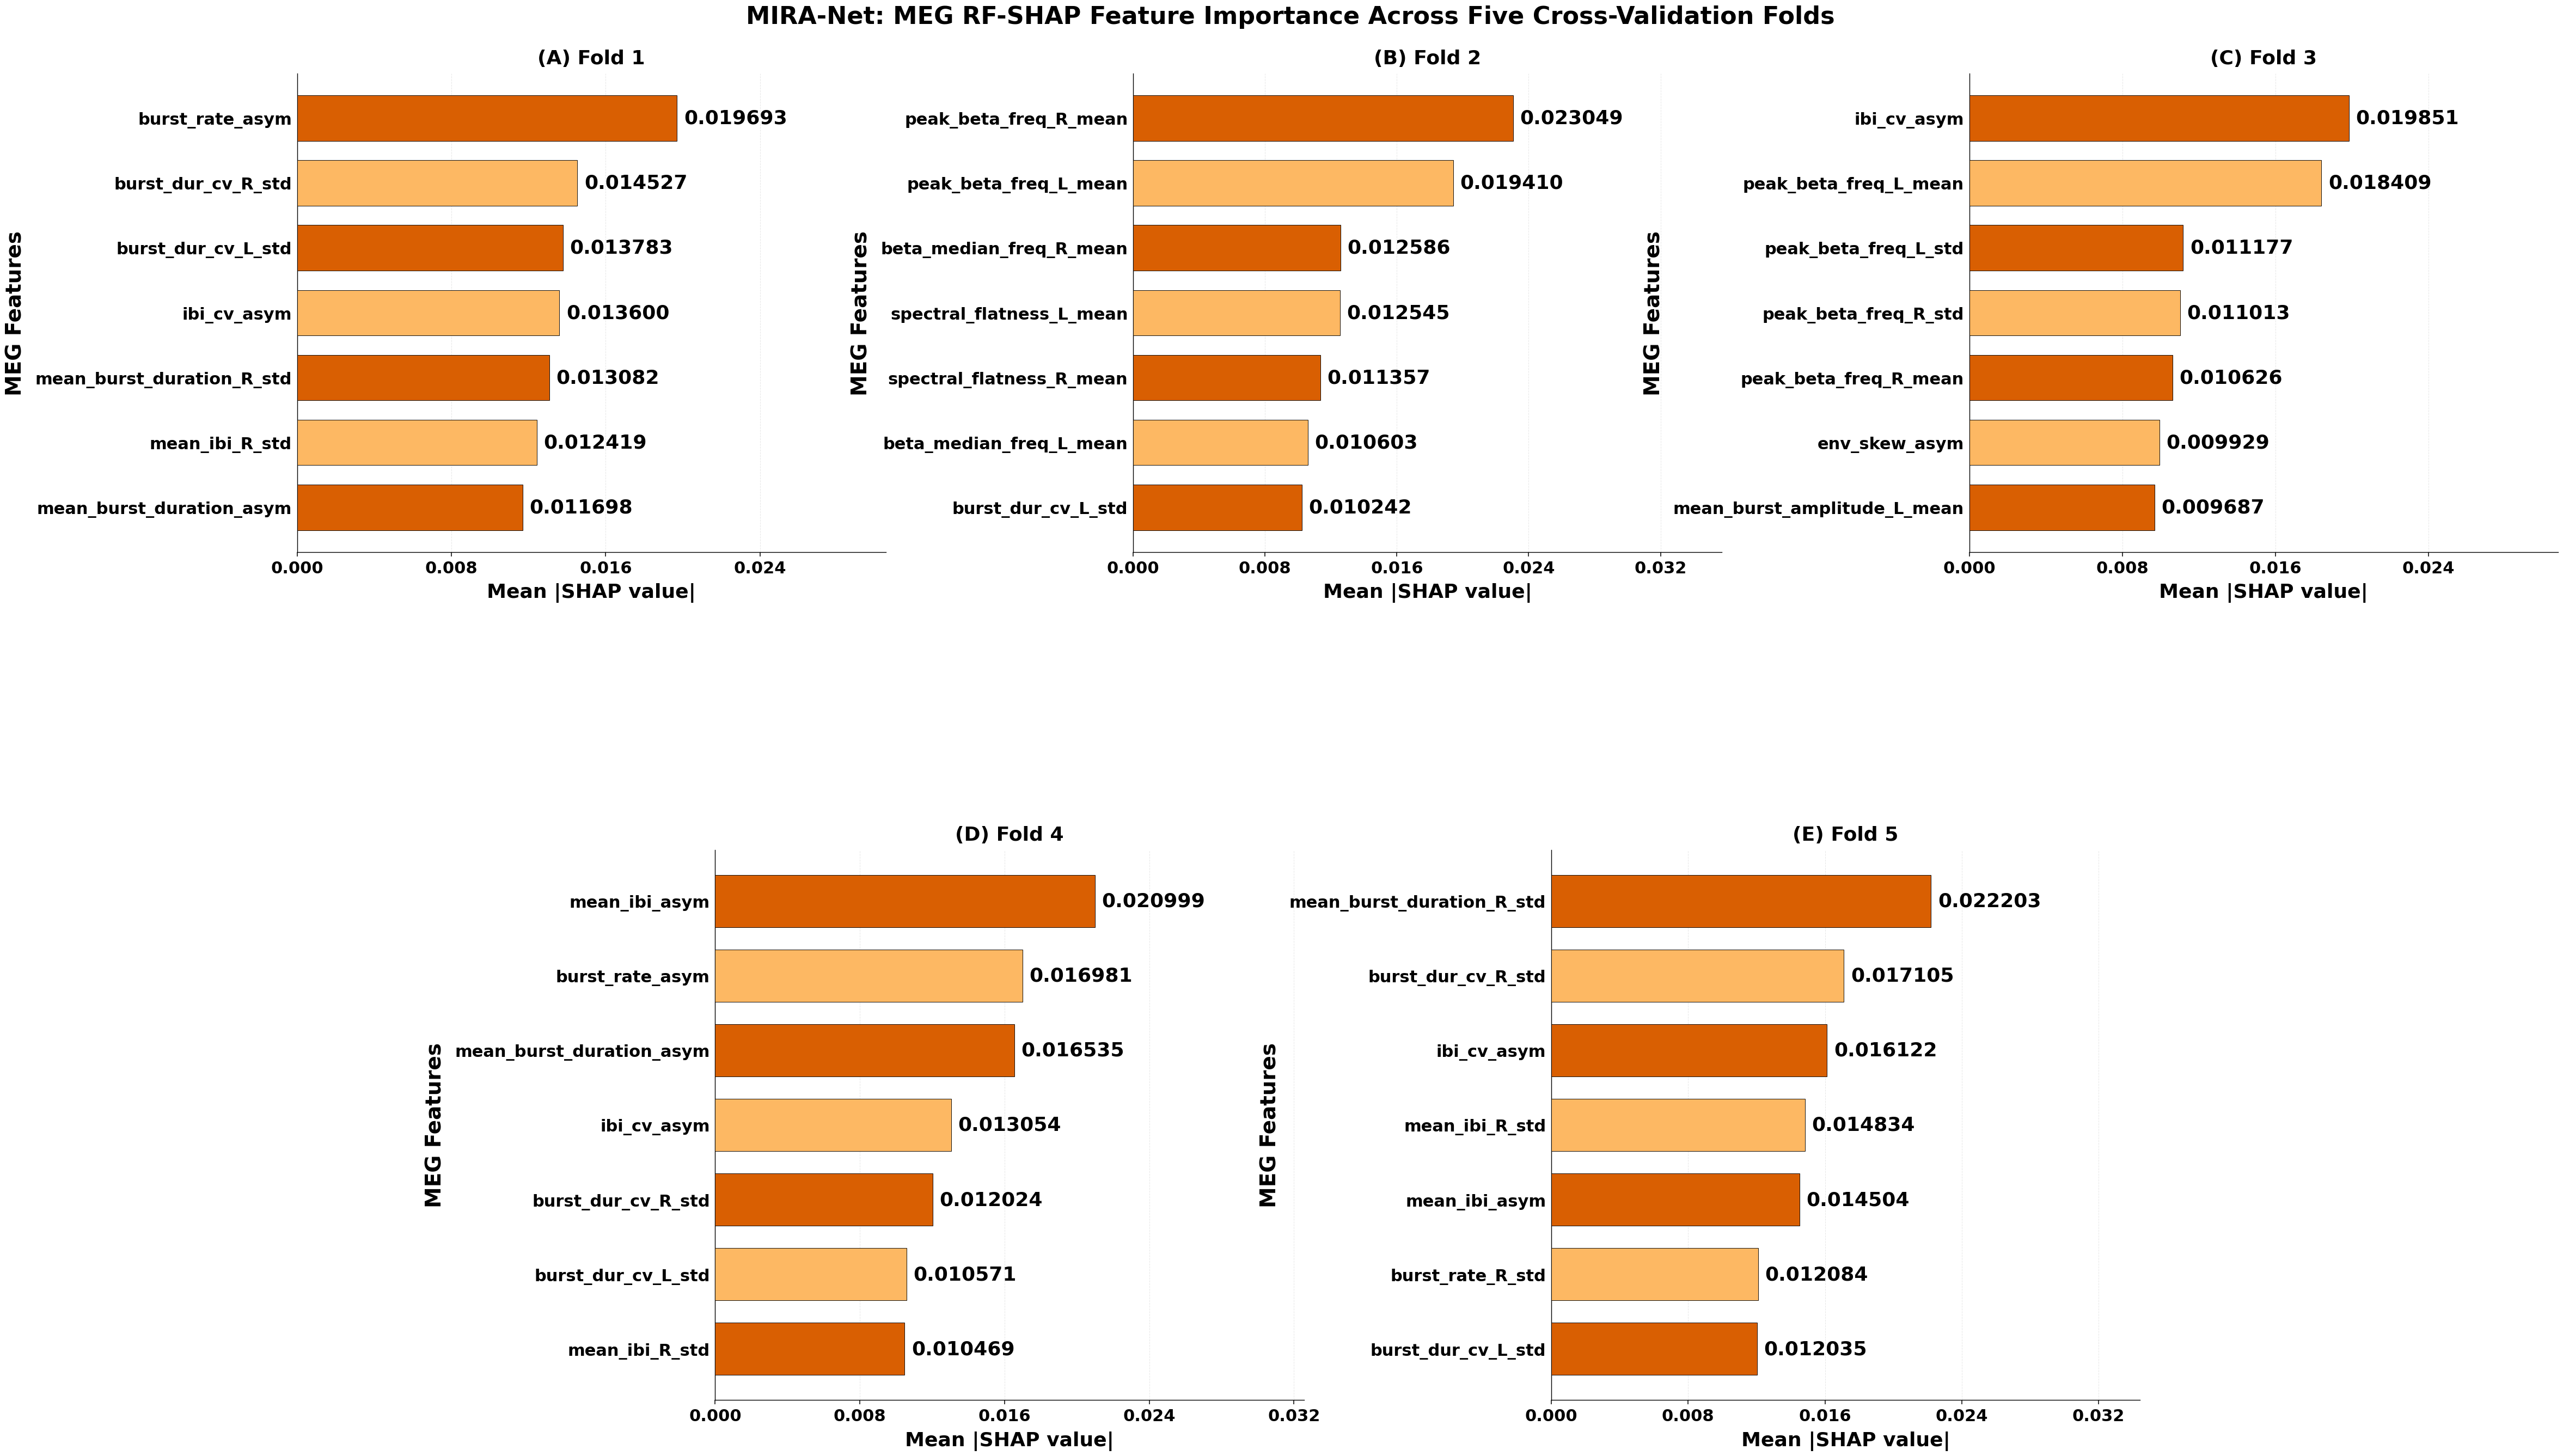


Completed successfully.


In [8]:

import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import MaxNLocator, MultipleLocator

# ============================================================
# MIRA-Net: MEG RF-SHAP FEATURE IMPORTANCE
#
# OUTPUTS:
# 1. Combined figure with five SHAP panels (PNG + PDF)
# 2. CSV containing fold-wise SHAP values
#
# PANELS A-E:
#   Horizontal bars, SHAP-style
#   Feature names on Y-axis
#   Mean absolute SHAP values on X-axis
#   Highest importance at the top
#
# Layout:
#   First row:  A, B, C
#   Second row: D, E (centred)
#
# Orange palette; 600-DPI PNG; vector PDF.
# ============================================================


# ============================================================
# 1. CONFIGURATION
# ============================================================

OUTPUT_DIR = "MIRA_Net_MEG_SHAP_Visualizations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DPI = 600

COLOR_PRIMARY = "#D95F02"
COLOR_SECONDARY = "#FDB863"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": DPI,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})


# ============================================================
# 2. FOLD-WISE TOP-7 MEG FEATURES AND SHAP VALUES
# ============================================================

fold_data = {
    "Fold 1": {
        "features": [
            "burst_rate_asym",
            "burst_dur_cv_R_std",
            "burst_dur_cv_L_std",
            "ibi_cv_asym",
            "mean_burst_duration_R_std",
            "mean_ibi_R_std",
            "mean_burst_duration_asym"
        ],
        "shap": [
            0.019693,
            0.014527,
            0.013783,
            0.013600,
            0.013082,
            0.012419,
            0.011698
        ]
    },

    "Fold 2": {
        "features": [
            "peak_beta_freq_R_mean",
            "peak_beta_freq_L_mean",
            "beta_median_freq_R_mean",
            "spectral_flatness_L_mean",
            "spectral_flatness_R_mean",
            "beta_median_freq_L_mean",
            "burst_dur_cv_L_std"
        ],
        "shap": [
            0.023049,
            0.019410,
            0.012586,
            0.012545,
            0.011357,
            0.010603,
            0.010242
        ]
    },

    "Fold 3": {
        "features": [
            "ibi_cv_asym",
            "peak_beta_freq_L_mean",
            "peak_beta_freq_L_std",
            "peak_beta_freq_R_std",
            "peak_beta_freq_R_mean",
            "env_skew_asym",
            "mean_burst_amplitude_L_mean"
        ],
        "shap": [
            0.019851,
            0.018409,
            0.011177,
            0.011013,
            0.010626,
            0.009929,
            0.009687
        ]
    },

    "Fold 4": {
        "features": [
            "mean_ibi_asym",
            "burst_rate_asym",
            "mean_burst_duration_asym",
            "ibi_cv_asym",
            "burst_dur_cv_R_std",
            "burst_dur_cv_L_std",
            "mean_ibi_R_std"
        ],
        "shap": [
            0.020999,
            0.016981,
            0.016535,
            0.013054,
            0.012024,
            0.010571,
            0.010469
        ]
    },

    "Fold 5": {
        "features": [
            "mean_burst_duration_R_std",
            "burst_dur_cv_R_std",
            "ibi_cv_asym",
            "mean_ibi_R_std",
            "mean_ibi_asym",
            "burst_rate_R_std",
            "burst_dur_cv_L_std"
        ],
        "shap": [
            0.022203,
            0.017105,
            0.016122,
            0.014834,
            0.014504,
            0.012084,
            0.012035
        ]
    }
}


# ============================================================
# 3. EXPORT FOLD-WISE SHAP DATA
# ============================================================

records = []

for fold_name, data in fold_data.items():
    for rank, (feature, shap_value) in enumerate(
        zip(data["features"], data["shap"]), start=1
    ):
        records.append({
            "Fold": fold_name,
            "Rank": rank,
            "Feature": feature,
            "Mean_Absolute_SHAP": shap_value
        })

fold_df = pd.DataFrame(records)

fold_csv_path = os.path.join(
    OUTPUT_DIR,
    "MEG_RF_SHAP_Foldwise_Data.csv"
)

fold_df.to_csv(fold_csv_path, index=False)

print("=" * 70)
print("FOLD-WISE MEG SHAP DATA")
print("=" * 70)
print(fold_df.to_string(index=False))

print("\nTotal fold-wise selections:", len(fold_df))
print("Expected selections: 35")
print("Actual selections:", len(fold_df))

assert len(fold_df) == 35, (
    "Expected 7 feature selections in each of 5 folds."
)

print(f"\nSaved fold-wise CSV: {os.path.abspath(fold_csv_path)}")


# ============================================================
# 5. HELPER FUNCTION: STYLE AXES
# Font sizes preserved exactly as in the supplied code.
# ============================================================

def style_axes(ax):

    ax.tick_params(
        axis="x",
        labelsize=22,
        width=1.1,
        length=6,
        colors="black",
        pad=5
    )

    ax.tick_params(
        axis="y",
        labelsize=22,
        width=1.0,
        length=0,
        colors="black",
        pad=7
    )

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.7,
        alpha=0.30,
        zorder=0
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)


# ============================================================
# 6. HELPER FUNCTION: DRAW SHAP BAR CHARTS
# Font sizes preserved; annotation room increased.
# ============================================================

def draw_shap_bars(ax, features, shap_values, title):

    features = list(features)
    shap_values = np.asarray(shap_values, dtype=float)

    # Sort ascending so the largest bar appears at the top
    order = np.argsort(shap_values)

    sorted_features = [features[i] for i in order]
    sorted_values = shap_values[order]

    colors = [
        COLOR_PRIMARY if i % 2 == 0 else COLOR_SECONDARY
        for i in range(len(sorted_features))
    ]

    y_positions = np.arange(len(sorted_features))

    bars = ax.barh(
        y_positions,
        sorted_values,
        color=colors,
        edgecolor="black",
        linewidth=0.65,
        height=0.70,
        zorder=3
    )

    ax.set_yticks(y_positions)

    ax.set_yticklabels(
        sorted_features,
        fontsize=12,
        fontweight="bold",
        color="black"
    )

    max_value = float(np.max(sorted_values))

    # Increased right-side space for numeric annotations
    ax.set_xlim(0, max_value * 1.55)

    # SHAP importance annotations: original font size preserved
    for bar, value in zip(bars, sorted_values):

        ax.text(
            value + max_value * 0.018,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.6f}",
            va="center",
            ha="left",
            fontsize=26,
            fontweight="bold",
            color="black",
            clip_on=False
        )

    ax.set_title(
        title,
        fontsize=26,
        fontweight="bold",
        color="black",
        pad=13
    )

    ax.set_xlabel(
        "Mean |SHAP value|",
        fontsize=26,
        fontweight="bold",
        color="black",
        labelpad=9
    )

    ax.set_ylabel(
        "MEG Features",
        fontsize=28,
        fontweight="black",
        color="black",
        labelpad=12
    )

    ax.tick_params(
        axis="x",
        labelsize=22
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))

    style_axes(ax)

    return ax


# ============================================================
# 7. CREATE THE FIVE-PANEL FIGURE
#
# Top row:    A, B, C
# Bottom row: D, E (centred)
#
# Larger canvas and increased spacing help avoid overlap.
# ============================================================

fig = plt.figure(figsize=(48, 28))

gs = gridspec.GridSpec(
    nrows=2,
    ncols=6,
    figure=fig,
    height_ratios=[1, 1.15],
    hspace=0.58,
    wspace=1.45
)

# PANEL A: FOLD 1
ax1 = fig.add_subplot(gs[0, 0:2])

draw_shap_bars(
    ax1,
    fold_data["Fold 1"]["features"],
    fold_data["Fold 1"]["shap"],
    "(A) Fold 1"
)

# PANEL B: FOLD 2
ax2 = fig.add_subplot(gs[0, 2:4])

draw_shap_bars(
    ax2,
    fold_data["Fold 2"]["features"],
    fold_data["Fold 2"]["shap"],
    "(B) Fold 2"
)

# PANEL C: FOLD 3
ax3 = fig.add_subplot(gs[0, 4:6])

draw_shap_bars(
    ax3,
    fold_data["Fold 3"]["features"],
    fold_data["Fold 3"]["shap"],
    "(C) Fold 3"
)

# PANEL D: FOLD 4 — centred bottom row
ax4 = fig.add_subplot(gs[1, 1:3])

draw_shap_bars(
    ax4,
    fold_data["Fold 4"]["features"],
    fold_data["Fold 4"]["shap"],
    "(D) Fold 4"
)

# PANEL E: FOLD 5 — centred bottom row
ax5 = fig.add_subplot(gs[1, 3:5])

draw_shap_bars(
    ax5,
    fold_data["Fold 5"]["features"],
    fold_data["Fold 5"]["shap"],
    "(E) Fold 5"
)


# ============================================================
# 8. OVERALL FIGURE TITLE
# Original font size preserved.
# ============================================================

fig.suptitle(
    "MIRA-Net: MEG RF-SHAP Feature Importance "
    "Across Five Cross-Validation Folds",
    fontsize=32,
    fontweight="bold",
    color="black",
    y=0.985
)


# ============================================================
# 9. FINAL LAYOUT ADJUSTMENTS
# ============================================================

fig.subplots_adjust(
    left=0.12,
    right=0.985,
    top=0.94,
    bottom=0.07,
    hspace=0.58,
    wspace=1.45
)


# ============================================================
# 10. SAVE COMBINED FIGURE
# ============================================================

combined_png = os.path.join(
    OUTPUT_DIR,
    "MEG_SHAP_Combined_2x3_Large.png"
)

combined_pdf = os.path.join(
    OUTPUT_DIR,
    "MEG_SHAP_Combined_2x3_Large.pdf"
)

# High-resolution PNG
fig.savefig(
    combined_png,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.20
)

# Vector PDF
fig.savefig(
    combined_pdf,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.20
)

print("\n" + "=" * 70)
print("MIRA-Net COMBINED MEG SHAP FIGURE GENERATED")
print("=" * 70)

print("\nCombined PNG:")
print(os.path.abspath(combined_png))

print("\nCombined PDF:")
print(os.path.abspath(combined_pdf))

print("\nCSV data files:")
print(os.path.abspath(fold_csv_path))
print(os.path.abspath(frequency_csv_path))

print("\nOutput directory:")
print(os.path.abspath(OUTPUT_DIR))

# Display the combined figure only
plt.show()
plt.close(fig)

print("\nCompleted successfully.")


In [9]:
from google.colab import files
import os

# Output directory created by your MIRA-Net code
OUTPUT_DIR = "MIRA_Net_MEG_SHAP_Visualizations"

# File paths
png_path = os.path.join(
    OUTPUT_DIR,
    "MEG_SHAP_Combined_2x3_Large.png"
)

pdf_path = os.path.join(
    OUTPUT_DIR,
    "MEG_SHAP_Combined_2x3_Large.pdf"
)

# Download high-resolution PNG
files.download(png_path)

# Download publication-ready PDF
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ACOUSTIC FEATURE-SELECTION FREQUENCY
Modality             Feature  Selection_Frequency  Percentage_of_Folds                         Selected_Folds
Acoustic Degree-voice breaks                    5                100.0 Fold 1, Fold 2, Fold 3, Fold 4, Fold 5
Acoustic        MDVP:Shimmer                    4                 80.0         Fold 1, Fold 2, Fold 3, Fold 5
Acoustic               MFCC5                    4                 80.0         Fold 1, Fold 2, Fold 4, Fold 5
Acoustic                RPDE                    4                 80.0         Fold 1, Fold 2, Fold 3, Fold 5
Acoustic No. of voice breaks                    3                 60.0                 Fold 1, Fold 4, Fold 5
Acoustic                 PPE                    3                 60.0                 Fold 3, Fold 4, Fold 5
Acoustic              Delta0                    2                 40.0                         Fold 1, Fold 3
Acoustic             Delta11                    2                 40.0             

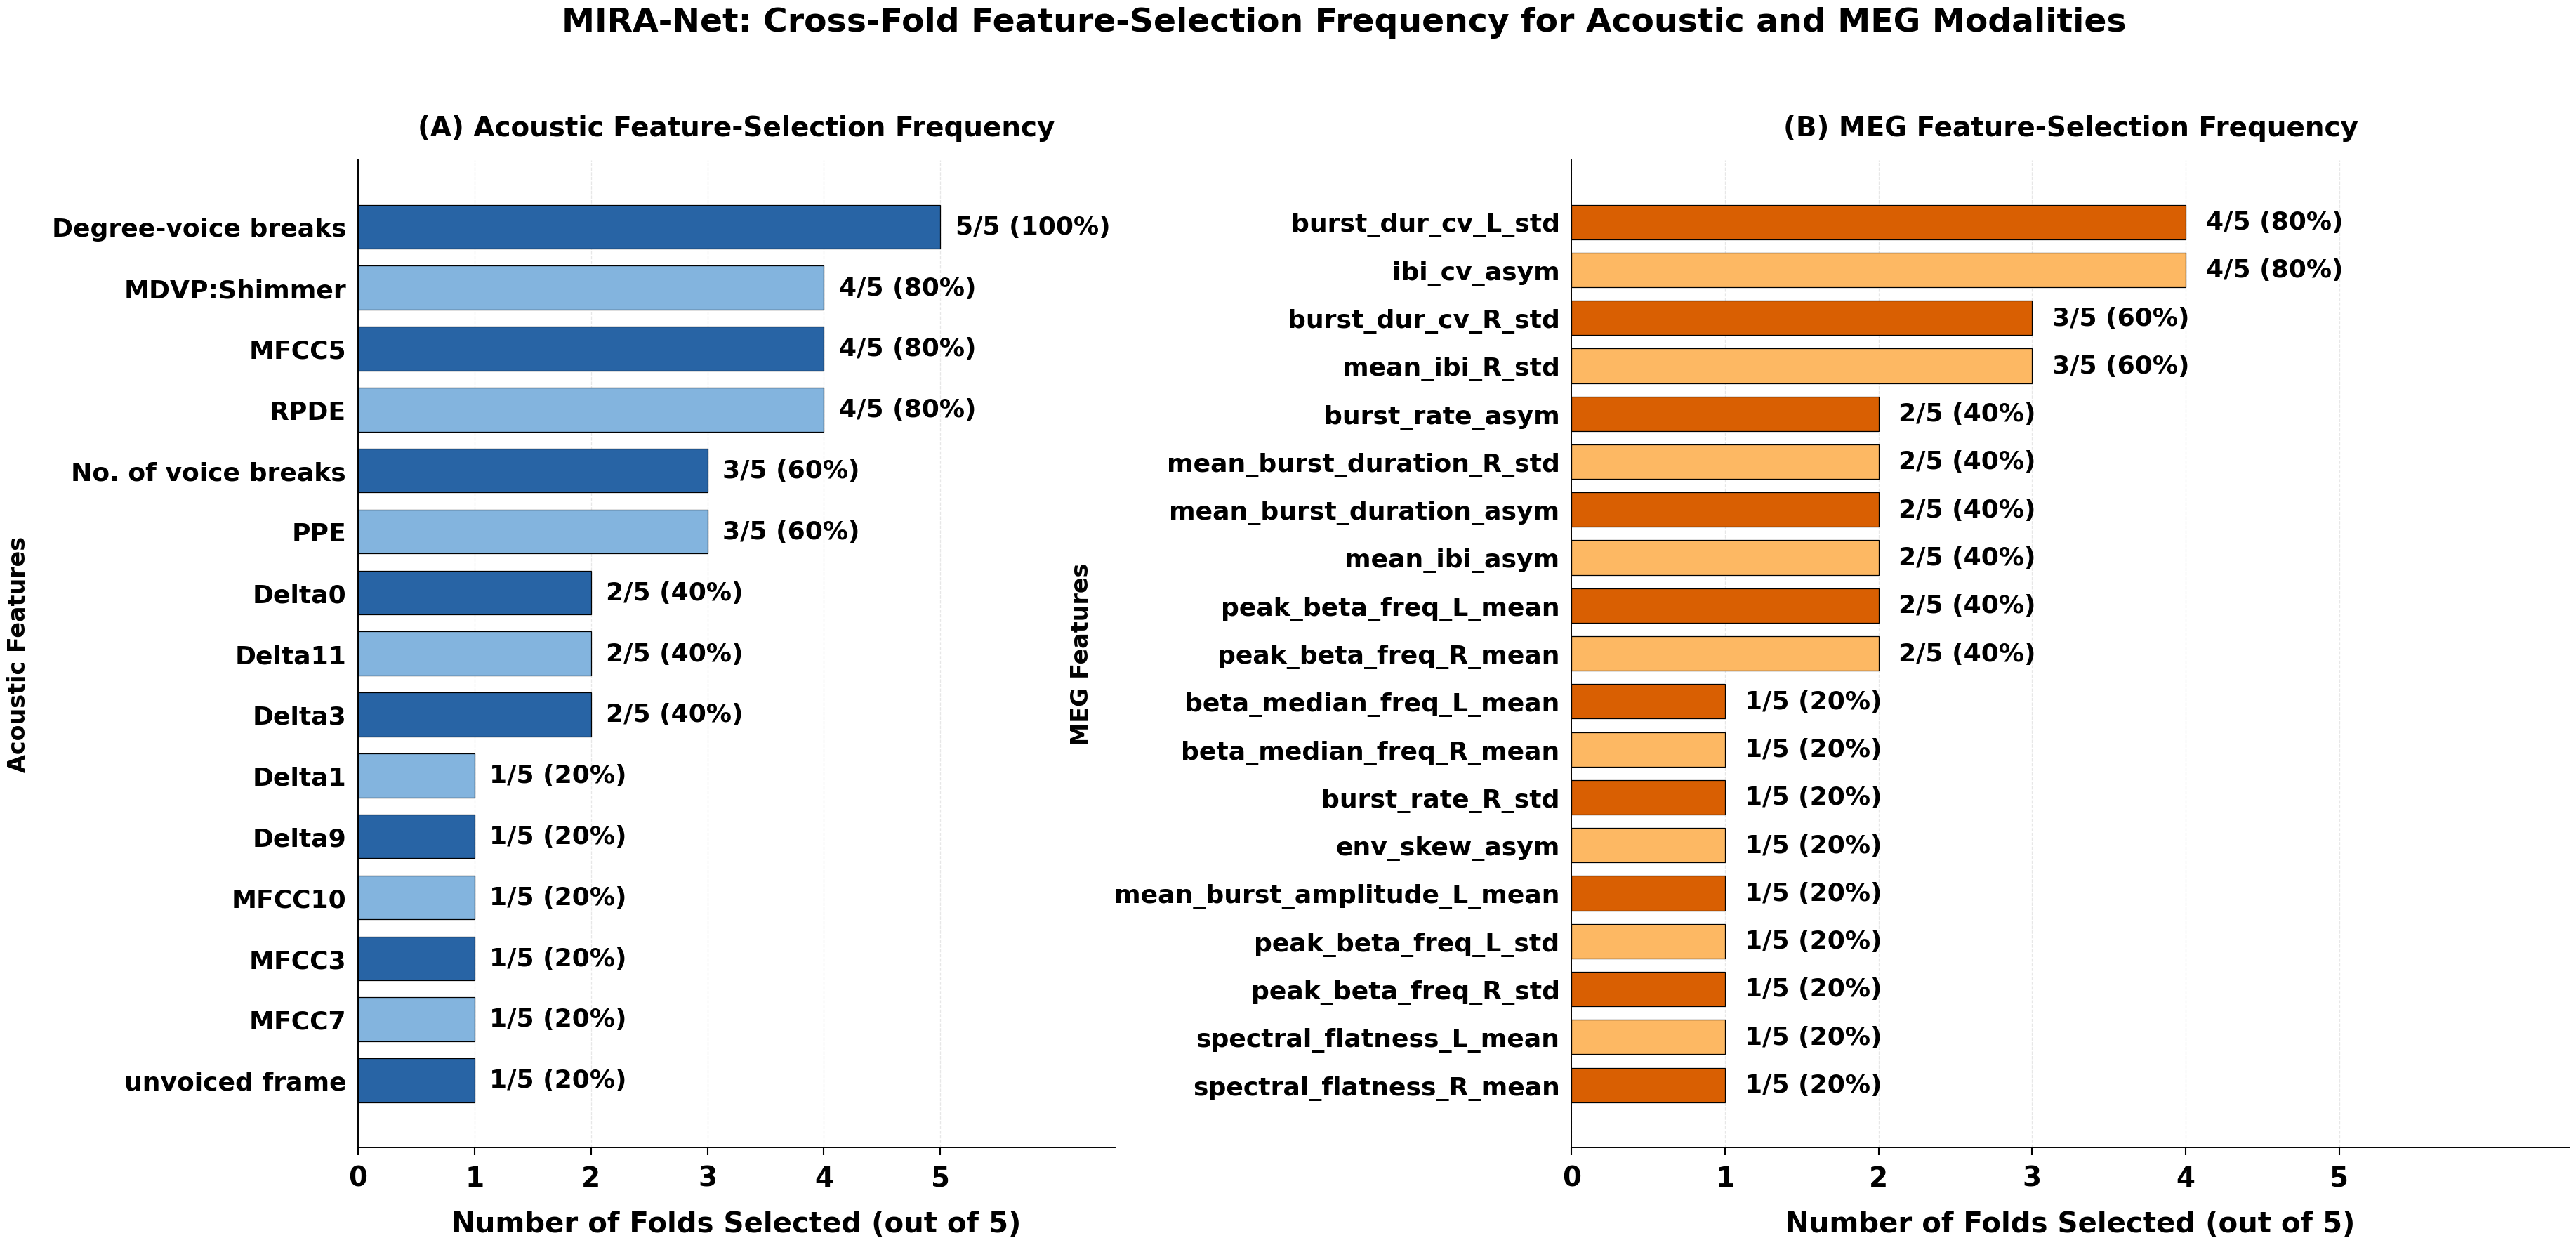


Completed successfully.


In [10]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# MIRA-Net: ACOUSTIC vs MEG FEATURE-SELECTION FREQUENCY
#
# PANEL A: Acoustic feature-selection frequency (BLUE)
# PANEL B: MEG feature-selection frequency      (ORANGE)
#
# Publication-ready formatting:
#   - Extra-large main and panel titles
#   - Extra-large X-axis title and tick labels
#   - Extra-large feature names
#   - Clear frequency annotations
#   - PNG at 600 DPI and vector PDF
#   - CSV exports for both modalities
# ============================================================


# ============================================================
# 1. CONFIGURATION
# ============================================================

OUTPUT_DIR = "MIRA_Net_Acoustic_MEG_Feature_Frequency"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DPI = 600

# Acoustic: blue shades
ACOUSTIC_PRIMARY = "#2864A5"
ACOUSTIC_SECONDARY = "#83B4DE"

# MEG: orange shades
MEG_PRIMARY = "#D95F02"
MEG_SECONDARY = "#FDB863"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 18,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "xtick.labelsize": 20,
    "ytick.labelsize": 18,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": DPI,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})


# ============================================================
# 2. ACOUSTIC TOP-7 FEATURES FROM EACH OUTER FOLD
# ============================================================

acoustic_fold_features = {
    "Fold 1": [
        "Degree-voice breaks",
        "MDVP:Shimmer",
        "Delta1",
        "RPDE",
        "Delta0",
        "No. of voice breaks",
        "MFCC5"
    ],

    "Fold 2": [
        "MDVP:Shimmer",
        "RPDE",
        "Delta11",
        "Delta3",
        "Degree-voice breaks",
        "MFCC5",
        "MFCC7"
    ],

    "Fold 3": [
        "Degree-voice breaks",
        "PPE",
        "Delta0",
        "Delta11",
        "MDVP:Shimmer",
        "Delta9",
        "RPDE"
    ],

    "Fold 4": [
        "PPE",
        "Degree-voice breaks",
        "MFCC5",
        "MFCC3",
        "No. of voice breaks",
        "unvoiced frame",
        "Delta3"
    ],

    "Fold 5": [
        "MFCC5",
        "PPE",
        "Degree-voice breaks",
        "MDVP:Shimmer",
        "RPDE",
        "No. of voice breaks",
        "MFCC10"
    ]
}


# ============================================================
# 3. MEG TOP-7 FEATURES FROM EACH OUTER FOLD
# ============================================================

meg_fold_features = {
    "Fold 1": [
        "burst_rate_asym",
        "burst_dur_cv_R_std",
        "burst_dur_cv_L_std",
        "ibi_cv_asym",
        "mean_burst_duration_R_std",
        "mean_ibi_R_std",
        "mean_burst_duration_asym"
    ],

    "Fold 2": [
        "peak_beta_freq_R_mean",
        "peak_beta_freq_L_mean",
        "beta_median_freq_R_mean",
        "spectral_flatness_L_mean",
        "spectral_flatness_R_mean",
        "beta_median_freq_L_mean",
        "burst_dur_cv_L_std"
    ],

    "Fold 3": [
        "ibi_cv_asym",
        "peak_beta_freq_L_mean",
        "peak_beta_freq_L_std",
        "peak_beta_freq_R_std",
        "peak_beta_freq_R_mean",
        "env_skew_asym",
        "mean_burst_amplitude_L_mean"
    ],

    "Fold 4": [
        "mean_ibi_asym",
        "burst_rate_asym",
        "mean_burst_duration_asym",
        "ibi_cv_asym",
        "burst_dur_cv_R_std",
        "burst_dur_cv_L_std",
        "mean_ibi_R_std"
    ],

    "Fold 5": [
        "mean_burst_duration_R_std",
        "burst_dur_cv_R_std",
        "ibi_cv_asym",
        "mean_ibi_R_std",
        "mean_ibi_asym",
        "burst_rate_R_std",
        "burst_dur_cv_L_std"
    ]
}


# ============================================================
# 4. CALCULATE FEATURE-SELECTION FREQUENCY
# ============================================================

def calculate_frequency(fold_features, modality_name):

    n_folds = len(fold_features)

    all_features = sorted({
        feature
        for features in fold_features.values()
        for feature in features
    })

    records = []

    for feature in all_features:

        selected_folds = [
            fold_name
            for fold_name, features in fold_features.items()
            if feature in features
        ]

        count = len(selected_folds)

        records.append({
            "Modality": modality_name,
            "Feature": feature,
            "Selection_Frequency": count,
            "Percentage_of_Folds": count / n_folds * 100,
            "Selected_Folds": ", ".join(selected_folds)
        })

    frequency_df = pd.DataFrame(records)

    frequency_df = frequency_df.sort_values(
        by=["Selection_Frequency", "Feature"],
        ascending=[False, True]
    ).reset_index(drop=True)

    return frequency_df


acoustic_frequency_df = calculate_frequency(
    acoustic_fold_features,
    "Acoustic"
)

meg_frequency_df = calculate_frequency(
    meg_fold_features,
    "MEG"
)


# ============================================================
# 5. VALIDATE FEATURE COUNTS
# ============================================================

assert len(acoustic_fold_features) == 5
assert len(meg_fold_features) == 5

assert all(
    len(features) == 7
    for features in acoustic_fold_features.values()
)

assert all(
    len(features) == 7
    for features in meg_fold_features.values()
)

assert acoustic_frequency_df["Selection_Frequency"].sum() == 35
assert meg_frequency_df["Selection_Frequency"].sum() == 35

assert acoustic_frequency_df["Feature"].nunique() == 15
assert meg_frequency_df["Feature"].nunique() == 19


# ============================================================
# 6. EXPORT FREQUENCY TABLES TO CSV
# ============================================================

acoustic_csv = os.path.join(
    OUTPUT_DIR,
    "Acoustic_Feature_Selection_Frequency.csv"
)

meg_csv = os.path.join(
    OUTPUT_DIR,
    "MEG_Feature_Selection_Frequency.csv"
)

acoustic_frequency_df.to_csv(acoustic_csv, index=False)
meg_frequency_df.to_csv(meg_csv, index=False)

print("=" * 80)
print("ACOUSTIC FEATURE-SELECTION FREQUENCY")
print("=" * 80)
print(acoustic_frequency_df.to_string(index=False))

print("\n" + "=" * 80)
print("MEG FEATURE-SELECTION FREQUENCY")
print("=" * 80)
print(meg_frequency_df.to_string(index=False))

print("\nAcoustic unique features:",
      acoustic_frequency_df["Feature"].nunique())

print("MEG unique features:",
      meg_frequency_df["Feature"].nunique())

print("\nTotal acoustic selections:",
      acoustic_frequency_df["Selection_Frequency"].sum())

print("Total MEG selections:",
      meg_frequency_df["Selection_Frequency"].sum())


# ============================================================
# 7. COMMON AXIS STYLING
# ============================================================

def style_axes(ax):

    # Extra-large X-axis tick numbers
    ax.tick_params(
        axis="x",
        labelsize=28,
        width=1.5,
        length=8,
        colors="black",
        pad=10
    )

    # Extra-large feature names
    ax.tick_params(
        axis="y",
        labelsize=26,
        width=1.3,
        length=0,
        colors="black",
        pad=12
    )

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.9,
        alpha=0.30,
        zorder=0
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)


# ============================================================
# 8. DRAW FEATURE-FREQUENCY PANEL
# ============================================================

def draw_frequency_panel(
    ax,
    frequency_df,
    title,
    modality_label,
    color_primary,
    color_secondary
):

    # Highest-frequency features appear at the top
    plot_df = frequency_df.sort_values(
        by=["Selection_Frequency", "Feature"],
        ascending=[True, False]
    ).reset_index(drop=True)

    features = plot_df["Feature"].tolist()

    counts = plot_df[
        "Selection_Frequency"
    ].to_numpy(dtype=int)

    percentages = plot_df[
        "Percentage_of_Folds"
    ].to_numpy(dtype=float)

    y_positions = np.arange(len(features))

    colors = [
        color_primary if i % 2 == 0 else color_secondary
        for i in range(len(features))
    ]

    bars = ax.barh(
        y_positions,
        counts,
        color=colors,
        edgecolor="black",
        linewidth=0.9,
        height=0.72,
        zorder=3
    )

    # Extra-large feature names
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        features,
        fontsize=19,
        fontweight="bold",
        color="black"
    )

    # Same frequency scale for both modalities
    ax.set_xlim(0, 6.5)
    ax.set_xticks(np.arange(0, 6, 1))

    # Frequency and percentage annotations
    for bar, count, percentage in zip(
        bars, counts, percentages
    ):
        ax.text(
            bar.get_width() + 0.13,
            bar.get_y() + bar.get_height() / 2,
            f"{count}/5 ({percentage:.0f}%)",
            va="center",
            ha="left",
            fontsize=26,
            fontweight="bold",
            color="black",
            clip_on=False
        )

    # Larger panel titles
    ax.set_title(
        title,
        fontsize=28,
        fontweight="bold",
        color="black",
        pad=25
    )

    # Extra-large X-axis title
    ax.set_xlabel(
        "Number of Folds Selected (out of 5)",
        fontsize=29,
        fontweight="bold",
        color="black",
        labelpad=19
    )

    # Large Y-axis title
    ax.set_ylabel(
        f"{modality_label} Features",
        fontsize=24,
        fontweight="bold",
        color="black",
        labelpad=22
    )

    style_axes(ax)


# ============================================================
# 9. CREATE COMBINED TWO-PANEL FIGURE
# ============================================================

# Larger canvas gives the enlarged labels more room
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(36, 19),
    gridspec_kw={
        "width_ratios": [1.10, 1.45],
        "wspace": 0.52
    }
)


# ============================================================
# PANEL A: ACOUSTIC (BLUE)
# ============================================================

draw_frequency_panel(
    ax=ax1,
    frequency_df=acoustic_frequency_df,
    title="(A) Acoustic Feature-Selection Frequency",
    modality_label="Acoustic",
    color_primary=ACOUSTIC_PRIMARY,
    color_secondary=ACOUSTIC_SECONDARY
)


# ============================================================
# PANEL B: MEG (ORANGE)
# ============================================================

draw_frequency_panel(
    ax=ax2,
    frequency_df=meg_frequency_df,
    title="(B) MEG Feature-Selection Frequency",
    modality_label="MEG",
    color_primary=MEG_PRIMARY,
    color_secondary=MEG_SECONDARY
)


# ============================================================
# 10. MAIN FIGURE TITLE
# ============================================================

fig.suptitle(
    "MIRA-Net: Cross-Fold Feature-Selection Frequency "
    "for Acoustic and MEG Modalities",
    fontsize=34,
    fontweight="bold",
    color="black",
    y=0.985
)


# ============================================================
# 11. FINAL LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.11,
    right=0.985,
    top=0.87,
    bottom=0.13,
    wspace=0.52
)


# ============================================================
# 12. SAVE PNG AND PDF
# ============================================================

combined_png = os.path.join(
    OUTPUT_DIR,
    "MIRA_Net_Acoustic_MEG_Feature_Frequency_600dpi.png"
)

combined_pdf = os.path.join(
    OUTPUT_DIR,
    "MIRA_Net_Acoustic_MEG_Feature_Frequency.pdf"
)

fig.savefig(
    combined_png,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.30
)

fig.savefig(
    combined_pdf,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.30
)


# ============================================================
# 13. PRINT OUTPUT PATHS
# ============================================================

print("\n" + "=" * 80)
print("COMBINED ACOUSTIC + MEG FEATURE-FREQUENCY FIGURE SAVED")
print("=" * 80)

print("\nCombined PNG (600 DPI):")
print(os.path.abspath(combined_png))

print("\nCombined PDF (vector format):")
print(os.path.abspath(combined_pdf))

print("\nAcoustic frequency CSV:")
print(os.path.abspath(acoustic_csv))

print("\nMEG frequency CSV:")
print(os.path.abspath(meg_csv))

print("\nOutput directory:")
print(os.path.abspath(OUTPUT_DIR))

plt.show()
plt.close(fig)

print("\nCompleted successfully.")


# ============================================================
# 14. OPTIONAL: DOWNLOAD FILES IN GOOGLE COLAB
# Uncomment these lines if using Google Colab.
# ============================================================

# from google.colab import files
# files.download(combined_png)
# files.download(combined_pdf)
# files.download(acoustic_csv)
# files.download(meg_csv)


In [11]:
from google.colab import files

files.download(combined_png)   # High-resolution PNG (600 DPI)
files.download(combined_pdf)   # PDF figure
files.download(acoustic_csv)   # Acoustic feature-frequency CSV
files.download(meg_csv)        # MEG feature-frequency CSV

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>